In [97]:
import yfinance as yf
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import datetime
import optuna
import backtrader as bt
from lightgbm import LGBMClassifier
from sklearn.metrics import log_loss
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection._split import _BaseKFold
import pandas_ta as ta
from sklearn.metrics import classification_report, roc_auc_score, roc_curve
from sklearn.model_selection import TimeSeriesSplit


[*********************100%***********************]  1 of 1 completed


Price                   Close      High       Low      Open  Volume
Datetime                                                           
2026-10-15 02:00:00  29789.25  29942.75  29765.50  29877.75   77648
2026-10-15 03:00:00  29838.50  30182.75  29753.50  29789.75   65372
2026-10-15 04:00:00  29781.50  29846.00  29768.75  29838.50   19988
(11484, 5)


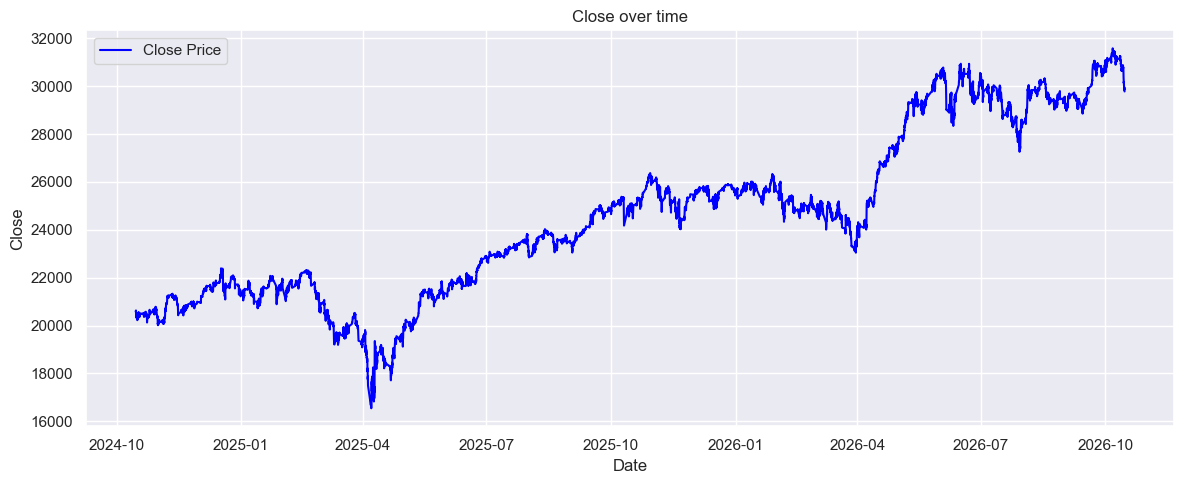

In [51]:
mnq_hr = yf.download("MNQ=F", period='max', interval='1h')
mnq_hr.index = mnq_hr.index.tz_localize(None)
mnq_hr.columns = mnq_hr.columns.droplevel(1)
print(mnq_hr.tail(3))
print(mnq_hr.shape)
sns.set_theme(style="darkgrid")
fig, ax = plt.subplots(figsize=(12,5))
sns.lineplot(data=mnq_hr, x='Datetime', y="Close", label='Close Price', color='blue')
plt.title('Close over time')
plt.xlabel("Date")
plt.ylabel("Close")
plt.tight_layout()
plt.show()

In [ ]:
def ml_features_mnq(mnq_hr, target_col='Close', lags=12):
  df_ml = mnq_hr.copy()
  df_ml['Hour'] = df_ml.index.hour

  
  df_ml['return_1'] = df_ml[target_col].pct_change(1)
  df_ml['return_3'] = df_ml[target_col].pct_change(3)
  df_ml['return_6'] = df_ml[target_col].pct_change(6)
  df_ml['return_12'] = df_ml[target_col].pct_change(12)
  df_ml['return_24'] = df_ml[target_col].pct_change(24)

  df_ml['SMA_10'] = ta.sma(df_ml[target_col], length=10)
  df_ml['SMA_20'] = ta.sma(df_ml[target_col], length=20)
  df_ml['SMA_50'] = ta.sma(df_ml[target_col], length=50)

  df_ml['EMA_10'] = ta.ema(df_ml[target_col], length=10)
  df_ml['EMA_20'] = ta.ema(df_ml[target_col], length=20)
  df_ml['EMA_50'] = ta.ema(df_ml[target_col], length=50)
  df_ml['EWMA_20'] = df_ml[target_col].ewm(span=20, adjust=False).mean()
  df_ml['EWMA_50'] = df_ml[target_col].ewm(span=50, adjust=False).mean()

  df_ml['close_SMA20'] = df_ml[target_col] / df_ml['SMA_20'] - 1
  df_ml['close_SMA50'] = df_ml[target_col] / df_ml['SMA_50'] - 1
  df_ml['close_EMA20'] = df_ml[target_col] / df_ml['EMA_20'] - 1
  df_ml['close_EMA50'] = df_ml[target_col] / df_ml['EMA_50'] - 1
  df_ml['close_EWMA20'] = df_ml[target_col] / df_ml['EWMA_20'] - 1
  df_ml['close_EWMA50'] = df_ml[target_col] / df_ml['EWMA_50'] - 1

  df_ml['RSI_7'] = ta.rsi(df_ml[target_col], length=7)
  df_ml['RSI_14'] = ta.rsi(df_ml[target_col], length=14)
  df_ml['RSI_28'] = ta.rsi(df_ml[target_col], length=28)

  
  df_ml['ATR'] = ta.atr(df_ml['High'], df_ml['Low'], df_ml['Close'], length=14)
  df_ml['volatility_regime'] = (
      df_ml['ATR'] > df_ml['ATR'].rolling(50).mean()
  ).astype(int)

  macd = ta.macd(df_ml[target_col])
  df_ml['MACD'] = macd['MACD_12_26_9']
  df_ml['MACD_signal'] = macd['MACDs_12_26_9']
  df_ml['MACD_hist'] = macd['MACDh_12_26_9']

  df_ml['volatility_6'] = df_ml['return_1'].rolling(6).std()
  df_ml['volatility_12'] = df_ml['return_1'].rolling(12).std()
  df_ml['volatility_24'] = df_ml['return_1'].rolling(24).std()

  df_ml['range'] = (df_ml['High'] - df_ml['Low']) / df_ml[target_col]
  df_ml['open_close'] = (df_ml['Close'] - df_ml['Open']) / df_ml['Open']
  df_ml['volume_change'] = df_ml['Volume'].pct_change()
  df_ml['volume_sma20'] = df_ml['Volume'].rolling(20).mean()
  df_ml['relative_volume'] = df_ml['Volume'] / df_ml['volume_sma20']

  
  lag_columns = [
      'return_1',
      'return_3',
      'RSI_14',
      'MACD_hist',
      'volatility_12',
      'relative_volume',
  ]
  lag_features = {}
  for col in lag_columns:
    for lag in range(1, lags + 1):
      lag_features[f'{col}_lag{lag}'] = df_ml[col].shift(lag)

  lag_df = pd.DataFrame(lag_features, index=df_ml.index)
  df_ml = pd.concat([df_ml, lag_df], axis=1)


  for h in range(1, 7):
    future_price = df_ml[target_col].shift(-h)
    df_ml[f'Target_H{h}'] = np.where(
        future_price.isna(),
        np.nan,
        (future_price > df_ml[target_col]).astype(int),
    )

  df_ml = df_ml.dropna()
  return df_ml

In [ ]:
class PurgedKFold(_BaseKFold):
    def __init__(self, n_splits=5, t1=None, embargo_pct=0.01):
        super(PurgedKFold, self).__init__(n_splits, shuffle=False, random_state=None)
        self.t1 = t1
        self.embargo_pct = embargo_pct

    def split(self, X, y=None, groups=None):
        if not isinstance(X.index, pd.DatetimeIndex):
            raise ValueError("X index must be a pandas DatetimeIndex.")
            
        indices = np.arange(X.shape[0])
        n_samples = X.shape[0]
        
        test_starts = [(i * n_samples) // self.n_splits for i in range(self.n_splits)]
        test_ends = [((i + 1) * n_samples) // self.n_splits for i in range(self.n_splits)]
        
        for i in range(self.n_splits):
            t0, t1_idx = test_starts[i], test_ends[i]
            test_indices = indices[t0:t1_idx]
            
            test_start_time = X.index[t0]
            test_end_time = X.index[t1_idx - 1] if t1_idx < n_samples else X.index[-1]
            
            embargo_idx = int(n_samples * self.embargo_pct)
            if i < self.n_splits - 1:
                embargo_time = X.index[min(t1_idx + embargo_idx, n_samples - 1)]
            else:
                embargo_time = X.index[-1]
                
            train_indices = []
            for idx in indices:
                sample_time = X.index[idx]

                if test_start_time <= sample_time <= embargo_time:
                    continue
                    
                
                if self.t1 is not None and sample_time in self.t1.index:
                    event_end = self.t1.loc[sample_time]
                
                    if not (event_end < test_start_time or sample_time > test_end_time):
                        continue
                else:
                    
                    if not (sample_time < test_start_time or sample_time > test_end_time):
                        continue
                        
                train_indices.append(idx)
                
            yield np.array(train_indices), test_indices

In [ ]:
def compute_sample_weights(t1_series, price_index):
    concurrency = pd.Series(0, index=price_index)
    
    for start_t, end_t in t1_series.items():
        concurrency.loc[start_t:end_t] += 1
        
    weights = []

    for start_t, end_t in t1_series.items():
        u_t = 1.0 / concurrency.loc[start_t:end_t]
        weights.append(u_t.mean())
        
    return np.array(weights)

In [ ]:
def get_triple_barrier_labels(df, close_col='Close', high_col='High', low_col='Low', 
                              atr_col='ATR', mult=1.5, max_bars=6):
    
    close = df[close_col]
    high = df[high_col]
    low = df[low_col]
    atr = df[atr_col]
    
    labels = pd.Series(index=df.index, dtype=float)
    t1 = pd.Series(index=df.index, dtype='datetime64[ns]')
    
    prices = close.values
    highs = high.values
    lows = low.values
    atrs = atr.values
    times = df.index
    n = len(df)
    
    for i in range(n - max_bars):
        entry_price = prices[i]
        current_atr = atrs[i]
        
        if np.isnan(current_atr) or current_atr <= 0:
            continue
            
        upper_barrier = entry_price + (mult * current_atr)
        lower_barrier = entry_price - (mult * current_atr)
        
        end_idx = min(i + max_bars, n - 1)
        hit = 0 # 0 = time expired, 1 = profit, -1 = stop loss
        termination_time = times[end_idx]
        
        for j in range(i + 1, end_idx + 1):
            if highs[j] >= upper_barrier:
                hit = 1
                termination_time = times[j]
                break
            
            if lows[j] <= lower_barrier:
                hit = -1
                termination_time = times[j]
                break
                
        labels.iloc[i] = hit
        t1.iloc[i] = termination_time
        
    return labels, t1

In [ ]:
def ml_features_mnq_with_triple_barrier(mnq_hr, target_col='Close', lags=12, atr_mult=1.5, max_holding_bars=6):

    df_ml = mnq_hr.copy()
    df_ml['Hour'] = df_ml.index.hour

    df_ml['return_1'] = df_ml[target_col].pct_change(1)
    df_ml['return_3'] = df_ml[target_col].pct_change(3)
    df_ml['return_6'] = df_ml[target_col].pct_change(6)
    df_ml['return_12'] = df_ml[target_col].pct_change(12)
    df_ml['return_24'] = df_ml[target_col].pct_change(24)

    df_ml['SMA_20'] = ta.sma(df_ml[target_col], length=20)
    df_ml['SMA_50'] = ta.sma(df_ml[target_col], length=50)
    df_ml['EMA_20'] = ta.ema(df_ml[target_col], length=20)
    df_ml['EMA_50'] = ta.ema(df_ml[target_col], length=50)

    df_ml['close_SMA20'] = df_ml[target_col] / df_ml['SMA_20'] - 1
    df_ml['close_SMA50'] = df_ml[target_col] / df_ml['SMA_50'] - 1
    df_ml['close_EMA20'] = df_ml[target_col] / df_ml['EMA_20'] - 1
    df_ml['close_EMA50'] = df_ml[target_col] / df_ml['EMA_50'] - 1

    df_ml['RSI_7'] = ta.rsi(df_ml[target_col], length=7)
    df_ml['RSI_14'] = ta.rsi(df_ml[target_col], length=14)
    df_ml['RSI_28'] = ta.rsi(df_ml[target_col], length=28)

    df_ml['ATR'] = ta.atr(df_ml['High'], df_ml['Low'], df_ml['Close'], length=14)
    df_ml['volatility_regime'] = (df_ml['ATR'] > df_ml['ATR'].rolling(50).mean()).astype(int)

    macd = ta.macd(df_ml[target_col])
    df_ml['MACD'] = macd['MACD_12_26_9']
    df_ml['MACD_signal'] = macd['MACDs_12_26_9']
    df_ml['MACD_hist'] = macd['MACDh_12_26_9']

    df_ml['volatility_6'] = df_ml['return_1'].rolling(6).std()
    df_ml['volatility_12'] = df_ml['return_1'].rolling(12).std()
    df_ml['volatility_24'] = df_ml['return_1'].rolling(24).std()

    df_ml['range'] = (df_ml['High'] - df_ml['Low']) / df_ml[target_col]
    df_ml['open_close'] = (df_ml['Close'] - df_ml['Open']) / df_ml['Open']
    df_ml['relative_volume'] = df_ml['Volume'] / df_ml['Volume'].rolling(20).mean()

    lag_columns = ['return_1', 'return_3', 'RSI_14', 'MACD_hist', 'volatility_12', 'relative_volume']
    lag_features = {}
    for col in lag_columns:
        for lag in range(1, lags + 1):
            lag_features[f'{col}_lag{lag}'] = df_ml[col].shift(lag)

    df_ml = pd.concat([df_ml, pd.DataFrame(lag_features, index=df_ml.index)], axis=1)

    labels, t1 = get_triple_barrier_labels(
        df_ml, 
        close_col=target_col, 
        high_col='High', 
        low_col='Low', 
        atr_col='ATR', 
        mult=atr_mult, 
        max_bars=max_holding_bars
    )
    
    df_ml['Target'] = labels
    df_ml['t1'] = t1

    df_ml = df_ml.dropna(subset=['Target', 't1'])
    
    return df_ml

In [57]:
df_processed = ml_features_mnq_with_triple_barrier(mnq_hr)
feature_cols = [c for c in df_processed.columns if c not in ['Open', 'High', 'Low', 'Close', 'Volume', 'Target', 't1']]

X_features = df_processed[feature_cols]
y_labels = df_processed['Target'] 
t1_series = df_processed['t1']

y_binary = (y_labels == 1).astype(int)
cv = PurgedKFold(n_splits=5, t1=t1_series, embargo_pct=0.01)

In [58]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
sample_weights = compute_sample_weights(t1_series, X_features.index)

def objective(trial):
    y_binary = (y_labels == 1).astype(int)

    params = {
            'n_estimators': trial.suggest_int('n_estimators', 100, 300),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
            'max_depth': trial.suggest_int('max_depth', 2, 6),
            'num_leaves': trial.suggest_int('num_leaves', 4, 32),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
            'random_state': 42,
            'n_jobs': -1,
            'verbose': -1
        }
        
    
    fold_log_losses = []
    
    for train_idx, test_idx in cv.split(X_features):
        X_train, X_test = X_features.iloc[train_idx], X_features.iloc[test_idx]
        y_train, y_test = y_binary.iloc[train_idx], y_binary.iloc[test_idx]
        
        w_train = sample_weights[train_idx]
        
        model = LGBMClassifier(**params)
        model.fit(X_train, y_train, sample_weight=w_train)
        
        preds_proba = model.predict_proba(X_test)[:, 1]
        loss = log_loss(y_test, preds_proba)
        fold_log_losses.append(loss)
        
    return np.mean(fold_log_losses)

print("Starting Multi-Class Optuna Hyperparameter Search...")
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

print("\n--- Best Binary-Class Hyperparameters Found ---")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")
print(f"Best Mean Binary-Class Log Loss: {study.best_value:.4f}")

Starting Multi-Class Optuna Hyperparameter Search...


  0%|          | 0/30 [00:00<?, ?it/s]


--- Best Binary-Class Hyperparameters Found ---
  n_estimators: 130
  learning_rate: 0.041716586637578934
  max_depth: 3
  num_leaves: 10
  subsample: 0.9669751469234167
  colsample_bytree: 0.6207083082971597
  min_child_samples: 59
  reg_alpha: 0.0024099136848030633
  reg_lambda: 5.530636505318383
Best Mean Binary-Class Log Loss: 0.5500


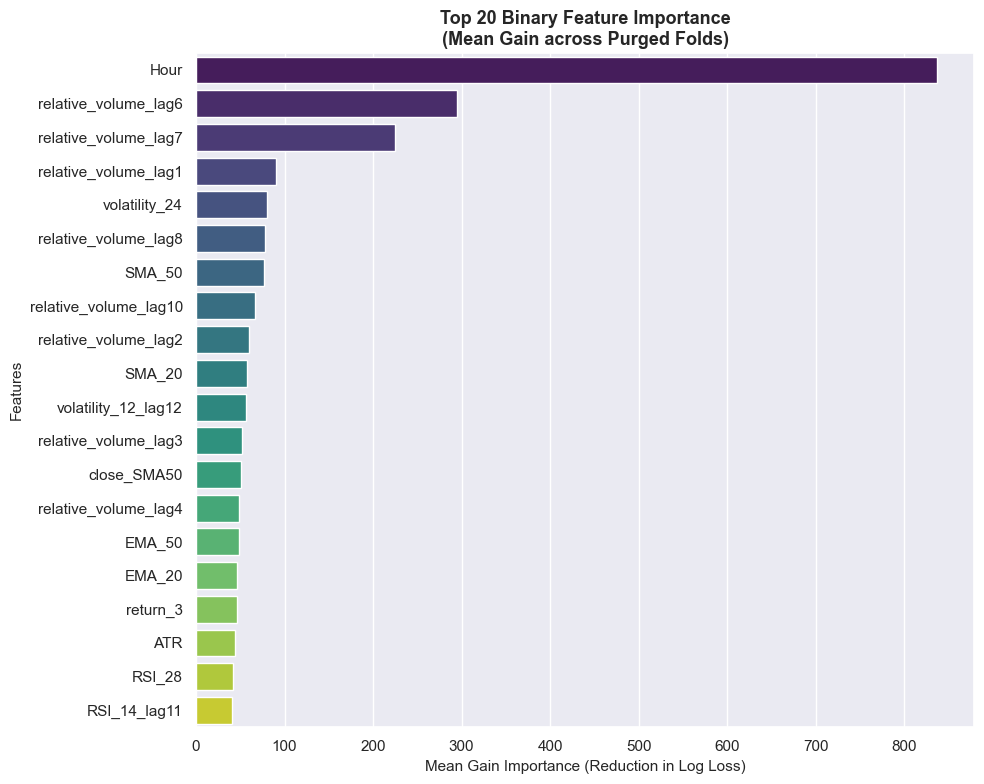

In [59]:
def get_cv_binary_feature_importances(X_features, y_binary, cv_splitter, sample_weights, best_params):
   
    feature_names = X_features.columns
    importance_df = pd.DataFrame(index=feature_names)
    
    fit_params = best_params.copy()
    fit_params['objective'] = 'binary'
    if 'num_class' in fit_params: del fit_params['num_class']
    fit_params['verbose'] = -1
    
    for fold, (train_idx, test_idx) in enumerate(cv_splitter.split(X_features)):
        X_train = X_features.iloc[train_idx]
        y_train = y_binary.iloc[train_idx]
        w_train = sample_weights[train_idx]
        
        model = LGBMClassifier(**fit_params)
        model.fit(X_train, y_train, sample_weight=w_train)
        
        importance_df[f'fold_{fold+1}'] = model.booster_.feature_importance(importance_type='gain')
        
    importance_df['mean_importance'] = importance_df.mean(axis=1)
    importance_df = importance_df.sort_values(by='mean_importance', ascending=False)
    
    return importance_df


sample_weights = compute_sample_weights(t1_series, X_features.index)
y_binary_labels_for_plot = (y_labels == 1).astype(int)

binary_cv_importances = get_cv_binary_feature_importances(
    X_features, 
    y_binary_labels_for_plot, 
    cv, 
    sample_weights, 
    study.best_params 
)

%matplotlib inline
plt.figure(figsize=(10, 8))
top_20_features = binary_cv_importances.head(20)

ax = sns.barplot(
    data=top_20_features,
    x='mean_importance',
    y=top_20_features.index,
    hue=top_20_features.index,
    palette='viridis',
    legend=False
)

plt.title('Top 20 Binary Feature Importance\n(Mean Gain across Purged Folds)', fontsize=13, fontweight='bold')
plt.xlabel('Mean Gain Importance (Reduction in Log Loss)', fontsize=11)
plt.ylabel('Features', fontsize=11)
plt.tight_layout()

plt.show()

=== Out-of-Fold (OOF) Evaluation Report ===
              precision    recall  f1-score   support

           0       0.73      0.98      0.83      8295
           1       0.45      0.05      0.09      3170

    accuracy                           0.72     11465
   macro avg       0.59      0.51      0.46     11465
weighted avg       0.65      0.72      0.63     11465

Out-of-Fold ROC-AUC: 0.6785


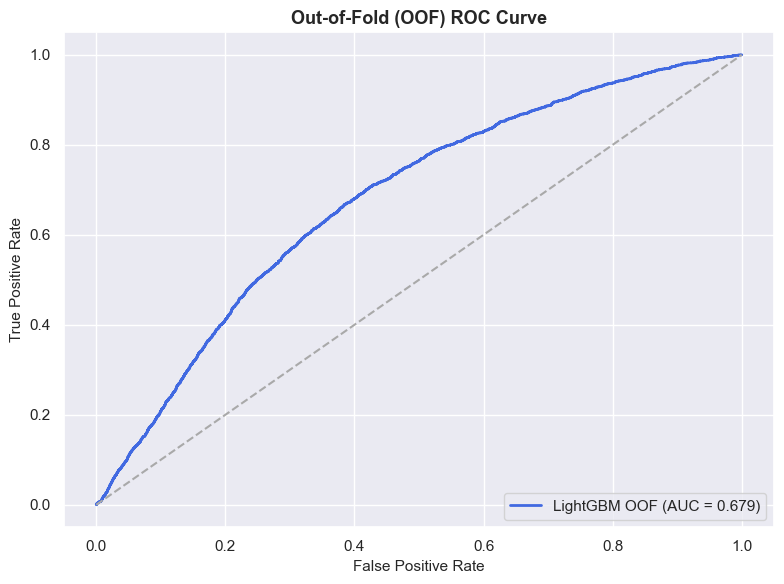

In [60]:
y_binary = (y_labels == 1).astype(int)
oof_probs = np.zeros(len(X_features))

best_params = study.best_params.copy()
best_params['objective'] = 'binary'
best_params['random_state'] = 42
best_params['n_jobs'] = -1
best_params['verbose'] = -1
for train_idx, test_idx in cv.split(X_features):
    X_train, X_test = X_features.iloc[train_idx], X_features.iloc[test_idx]
    y_train = y_binary.iloc[train_idx]
    w_train = sample_weights[train_idx]
    
    model = LGBMClassifier(**best_params)
    model.fit(X_train, y_train, sample_weight=w_train)
    oof_probs[test_idx] = model.predict_proba(X_test)[:, 1]

oof_auc = roc_auc_score(y_binary, oof_probs)
y_pred_binary = (oof_probs >= 0.5).astype(int)

print("=== Out-of-Fold (OOF) Evaluation Report ===")
print(classification_report(y_binary, y_pred_binary))
print(f"Out-of-Fold ROC-AUC: {oof_auc:.4f}")

fpr, tpr, _ = roc_curve(y_binary, oof_probs)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='royalblue', label=f'LightGBM OOF (AUC = {oof_auc:.3f})', linewidth=2)
plt.plot([0, 1], [0, 1], color='darkgray', linestyle='--')
plt.title('Out-of-Fold (OOF) ROC Curve', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [65]:
import backtrader as bt
import pandas as pd
import numpy as np

df_bt = df_processed.copy()
df_bt['prob_success'] = oof_probs

primary_longs = (
    (df_bt['Close'] > df_bt['Close'].ewm(span=50).mean()) & 
    (df_bt['ATR'] > df_bt['ATR'].rolling(20).mean())
)
threshold = pd.Series(oof_probs).quantile(0.80)
df_bt['signal'] = (primary_longs & (df_bt['prob_success'] >= threshold)).astype(int)

class MLATRData(bt.feeds.PandasData):
    lines = ('prob_success', 'signal', 'ATR')
    params = (
        ('prob_success', 'prob_success'),
        ('signal', 'signal'),
        ('ATR', 'ATR'),
    )

class DynamicATRBarrierStrategy(bt.Strategy):
    params = (
        ('tp_mult', 2.5),  # 2.5x ATR Take Profit
        ('sl_mult', 1.0),  # 1.0x ATR Stop Loss
        ('printlog', True),
    )

    def __init__(self):
        self.dataclose = self.datas[0].close
        self.prob_success = self.datas[0].prob_success
        self.signal = self.datas[0].signal
        self.atr = self.datas[0].ATR
        self.orefs = []

    def log(self, txt, dt=None):
        if self.params.printlog:
            dt = dt or self.datas[0].datetime.date(0)
            print(f'{dt.isoformat()} {txt}')

    def notify_order(self, order):
        if order.status in [order.Submitted, order.Accepted]:
            return

        if order.status in [order.Completed]:
            if order.isbuy():
                self.log(f'BUY EXECUTED (Entry), Price: {order.executed.price:.2f}')
            else:
                self.log(f'SELL EXECUTED (TP/SL Exit), Price: {order.executed.price:.2f}')

        if order.status in [order.Completed, order.Canceled, order.Margin, order.Rejected]:
            self.orefs = [ref for ref in self.orefs if ref != order.ref]

    def next(self):
        if self.orefs:
            return

        if not self.position:
            if self.signal[0] == 1:
                entry_price = self.dataclose[0]
                current_atr = self.atr[0]
                
                tp_distance = current_atr * self.params.tp_mult
                sl_distance = current_atr * self.params.sl_mult
                
                tp_price = entry_price + tp_distance
                sl_price = entry_price - sl_distance

                self.log(f'SIGNAL: Long at {entry_price:.2f} | ATR: {current_atr:.2f} | TP: {tp_price:.2f} | SL: {sl_price:.2f}')

                bracket = self.buy_bracket(
                    size=1,
                    price=entry_price,
                    exectype=bt.Order.Market,
                    stopprice=sl_price,
                    limitprice=tp_price
                )
                self.orefs = [o.ref for o in bracket]

cerebro = bt.Cerebro()
cerebro.addstrategy(DynamicATRBarrierStrategy)

data = MLATRData(
    dataname=df_bt,
    datetime=None,
    open='Open', high='High', low='Low', close='Close', volume='Volume'
)
cerebro.adddata(data)

cerebro.broker.setcash(10000.0)
cerebro.broker.setcommission(commission=0.62, margin=500.0, mult=2.0)

print(f'Starting Portfolio Value: ${cerebro.broker.getvalue():,.2f}')
cerebro.run()
print(f'Final Portfolio Value:   ${cerebro.broker.getvalue():,.2f}')


Starting Portfolio Value: $10,000.00
2024-10-22 SIGNAL: Long at 20460.50 | ATR: 51.49 | TP: 20589.22 | SL: 20409.01
2024-10-22 BUY EXECUTED (Entry), Price: 20461.25
2024-10-22 SELL EXECUTED (TP/SL Exit), Price: 20589.22
2024-10-28 SIGNAL: Long at 20556.25 | ATR: 58.87 | TP: 20703.42 | SL: 20497.38
2024-10-28 BUY EXECUTED (Entry), Price: 20555.75
2024-10-28 SELL EXECUTED (TP/SL Exit), Price: 20497.38
2024-11-12 SIGNAL: Long at 21235.00 | ATR: 43.92 | TP: 21344.79 | SL: 21191.08
2024-11-12 BUY EXECUTED (Entry), Price: 21234.50
2024-11-12 SELL EXECUTED (TP/SL Exit), Price: 21184.00
2024-12-06 SIGNAL: Long at 21608.00 | ATR: 37.77 | TP: 21702.43 | SL: 21570.23
2024-12-06 BUY EXECUTED (Entry), Price: 21607.25
2024-12-09 SELL EXECUTED (TP/SL Exit), Price: 21702.43
2024-12-17 SIGNAL: Long at 22106.75 | ATR: 79.41 | TP: 22305.28 | SL: 22027.34
2024-12-17 BUY EXECUTED (Entry), Price: 22107.25
2024-12-17 SELL EXECUTED (TP/SL Exit), Price: 22305.28
2025-01-15 SIGNAL: Long at 21281.25 | ATR: 79.45

In [98]:
tscv = TimeSeriesSplit(n_splits=5)

wfo_probs = np.full(len(X_features), np.nan)

fold_idx = 1
for train_idx, test_idx in tscv.split(X_features):
    print(f"\n--- Walk-Forward Fold {fold_idx} ---")
    print(f"Train samples: {len(train_idx)} | Test samples: {len(test_idx)}")
    
    X_train, X_test = X_features.iloc[train_idx], X_features.iloc[test_idx]
    y_binary = (y_labels == 1).astype(int)
    y_train = y_binary.iloc[train_idx]
    
    w_train = compute_sample_weights(t1_series.iloc[train_idx], X_train.index)
    
    def objective_wfo(trial):
        params = {
            'n_estimators': trial.suggest_int('n_estimators', 100, 300),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
            'max_depth': trial.suggest_int('max_depth', 2, 6),
            'num_leaves': trial.suggest_int('num_leaves', 4, 32),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
            'random_state': 42,
            'n_jobs': -1,
            'verbose': -1
        }
        
        inner_tscv = TimeSeriesSplit(n_splits=3)
        inner_losses = []
        
        for in_train, in_val in inner_tscv.split(X_train):
            X_in_tr, X_in_va = X_train.iloc[in_train], X_train.iloc[in_val]
            y_in_tr, y_in_va = y_train.iloc[in_train], y_train.iloc[in_val]
            w_in_tr = w_train[in_train]
            
            m = LGBMClassifier(**params)
            m.fit(X_in_tr, y_in_tr, sample_weight=w_in_tr)
            preds = m.predict_proba(X_in_va)[:, 1]
            inner_losses.append(log_loss(y_in_va, preds))
            
        return np.mean(inner_losses)

    study = optuna.create_study(direction='minimize')
    study.optimize(objective_wfo, n_trials=15, show_progress_bar=False)
    
    best_params = study.best_params.copy()
    best_params['objective'] = 'binary'
    best_params['random_state'] = 42
    best_params['n_jobs'] = -1
    best_params['verbose'] = -1
    
    best_model = LGBMClassifier(**best_params)
    best_model.fit(X_train, y_train, sample_weight=w_train)
    
    wfo_probs[test_idx] = best_model.predict_proba(X_test)[:, 1]
    fold_idx += 1

print("\nWalk-Forward Optimization Complete!")


--- Walk-Forward Fold 1 ---
Train samples: 1915 | Test samples: 1910

--- Walk-Forward Fold 2 ---
Train samples: 3825 | Test samples: 1910

--- Walk-Forward Fold 3 ---
Train samples: 5735 | Test samples: 1910

--- Walk-Forward Fold 4 ---
Train samples: 7645 | Test samples: 1910

--- Walk-Forward Fold 5 ---
Train samples: 9555 | Test samples: 1910

Walk-Forward Optimization Complete!


In [100]:
df_wfo = df_processed.copy()
df_wfo['prob_success'] = wfo_probs
df_wfo = df_wfo.dropna(subset=['prob_success'])
primary_longs = (
    (df_wfo['Close'] > df_wfo['Close'].ewm(span=50).mean()) & 
    (df_wfo['ATR'] > df_wfo['ATR'].rolling(20).mean())
)
threshold = pd.Series(wfo_probs).quantile(0.80)
df_wfo['signal'] = (primary_longs & (df_wfo['prob_success'] >= threshold)).astype(int)
cerebro = bt.Cerebro()
cerebro.addstrategy(DynamicATRBarrierStrategy)

data = MLATRData(
    dataname=df_wfo,
    datetime=None,
    open='Open', high='High', low='Low', close='Close', volume='Volume'
)
cerebro.adddata(data)

cerebro.broker.setcash(10000.0)
cerebro.broker.setcommission(commission=0.62, margin=500.0, mult=2.0)

print(f'Starting WFO Portfolio Value: ${cerebro.broker.getvalue():,.2f}')
cerebro.run()
final_val_wfo = cerebro.broker.getvalue()
print(f'Final WFO Portfolio Value:    ${final_val_wfo:,.2f}')
print(f'Net WFO Strategy Return:      ${final_val_wfo - 10000.0:,.2f}')

Starting WFO Portfolio Value: $10,000.00
2025-03-17 SIGNAL: Long at 19686.75 | ATR: 78.82 | TP: 19883.80 | SL: 19607.93
2025-03-17 BUY EXECUTED (Entry), Price: 19687.75
2025-03-17 SELL EXECUTED (TP/SL Exit), Price: 19883.80
2025-03-18 SIGNAL: Long at 19772.00 | ATR: 90.72 | TP: 19998.79 | SL: 19681.28
2025-03-18 BUY EXECUTED (Entry), Price: 19981.25
2025-03-18 SELL EXECUTED (TP/SL Exit), Price: 19681.28
2025-03-19 SIGNAL: Long at 19721.00 | ATR: 233.62 | TP: 20305.05 | SL: 19487.38
2025-03-19 BUY EXECUTED (Entry), Price: 19721.00
2025-03-21 SELL EXECUTED (TP/SL Exit), Price: 19487.38
2025-04-01 SIGNAL: Long at 19516.00 | ATR: 98.30 | TP: 19761.76 | SL: 19417.70
2025-04-01 BUY EXECUTED (Entry), Price: 19515.75
2025-04-01 SELL EXECUTED (TP/SL Exit), Price: 19417.70
2025-04-02 SIGNAL: Long at 19633.00 | ATR: 91.23 | TP: 19861.08 | SL: 19541.77
2025-04-02 BUY EXECUTED (Entry), Price: 19632.75
2025-04-02 SELL EXECUTED (TP/SL Exit), Price: 19861.08
2025-04-09 SIGNAL: Long at 17445.50 | ATR: 

<h1>Removing Hour Column<h1>

In [62]:
import optuna
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier

if 'Hour' in X_features.columns:
    X_features_no_hr = X_features.drop(columns=['Hour'])
    print("Dropped 'Hour' from X_features.")

optuna.logging.set_verbosity(optuna.logging.WARNING)
sample_weights = compute_sample_weights(t1_series, X_features.index)

def objective_no_hour(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 2, 6),
        'num_leaves': trial.suggest_int('num_leaves', 4, 32),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'random_state': 42,
        'n_jobs': -1,
        'verbose': -1
    }
    
    y_binary = (y_labels == 1).astype(int)
    fold_log_losses = []

    for train_idx, test_idx in cv.split(X_features_no_hr):
        X_train, X_test = X_features_no_hr.iloc[train_idx], X_features_no_hr.iloc[test_idx]
        y_train, y_test = y_binary.iloc[train_idx], y_binary.iloc[test_idx]
        
        w_train = sample_weights[train_idx]
        
        model_no_hr = LGBMClassifier(**params)
        model_no_hr.fit(X_train, y_train, sample_weight=w_train)
        
        preds_proba = model_no_hr.predict_proba(X_test)[:, 1]
        loss = log_loss(y_test, preds_proba)
        fold_log_losses.append(loss)
        
    return np.mean(fold_log_losses)

print("Starting Multi-Class Optuna Hyperparameter Search (No Hour Model)...")
study_no_hr = optuna.create_study(direction='minimize')
study_no_hr.optimize(objective_no_hour, n_trials=30, show_progress_bar=True)

print("\n--- Best Binary-Class Hyperparameters Found ---")
for key, value in study_no_hr.best_params.items():
    print(f"  {key}: {value}")
print(f"Best Mean Binary-Class Log Loss: {study_no_hr.best_value:.4f}")

Dropped 'Hour' from X_features.
Starting Multi-Class Optuna Hyperparameter Search (No Hour Model)...


  0%|          | 0/30 [00:00<?, ?it/s]


--- Best Binary-Class Hyperparameters Found ---
  n_estimators: 188
  learning_rate: 0.01717381473719015
  max_depth: 6
  num_leaves: 22
  subsample: 0.8175753611197547
  colsample_bytree: 0.6450526984179183
  min_child_samples: 62
  reg_alpha: 0.0013409462957808948
  reg_lambda: 0.11530505488582643
Best Mean Binary-Class Log Loss: 0.5523


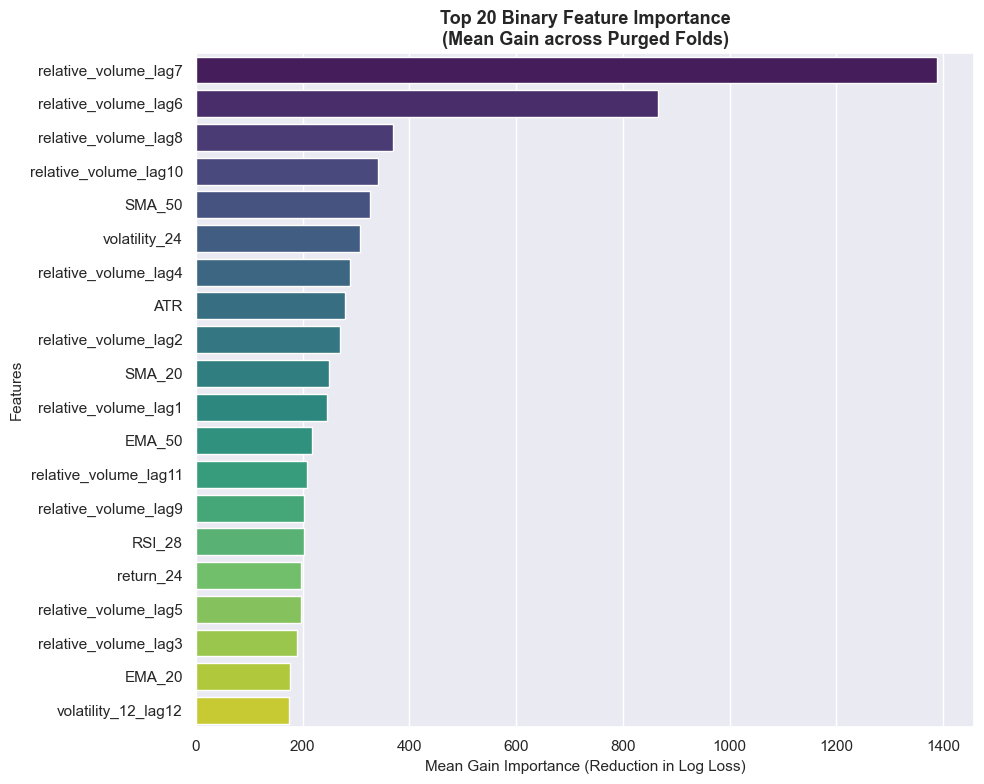

In [63]:
binary_cv_importances = get_cv_binary_feature_importances(
    X_features_no_hr, 
    y_binary_labels_for_plot, 
    cv, 
    sample_weights, 
    study_no_hr.best_params 
)

%matplotlib inline
plt.figure(figsize=(10, 8))
top_20_features = binary_cv_importances.head(20)

ax = sns.barplot(
    data=top_20_features,
    x='mean_importance',
    y=top_20_features.index,
    hue=top_20_features.index,
    palette='viridis',
    legend=False
)

plt.title('Top 20 Binary Feature Importance\n(Mean Gain across Purged Folds)', fontsize=13, fontweight='bold')
plt.xlabel('Mean Gain Importance (Reduction in Log Loss)', fontsize=11)
plt.ylabel('Features', fontsize=11)
plt.tight_layout()

plt.show()

=== Out-of-Fold (OOF) Evaluation Report ===
              precision    recall  f1-score   support

           0       0.73      0.97      0.83      8295
           1       0.40      0.06      0.11      3170

    accuracy                           0.72     11465
   macro avg       0.57      0.51      0.47     11465
weighted avg       0.64      0.72      0.63     11465

Out-of-Fold ROC-AUC: 0.6734


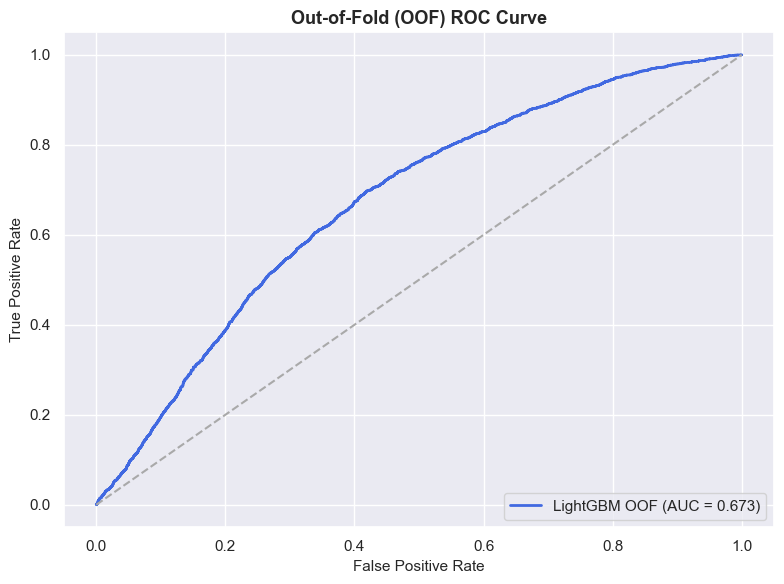

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, roc_auc_score, roc_curve

y_binary = (y_labels == 1).astype(int)
oof_probs_no_hr = np.zeros(len(X_features_no_hr))

best_params_no_hr = study_no_hr.best_params.copy()
best_params_no_hr['objective'] = 'binary'
best_params_no_hr['random_state'] = 42
best_params_no_hr['n_jobs'] = -1
best_params_no_hr['verbose'] = -1
for train_idx, test_idx in cv.split(X_features_no_hr):
    X_train, X_test = X_features_no_hr.iloc[train_idx], X_features_no_hr.iloc[test_idx]
    y_train = y_binary.iloc[train_idx]
    w_train = sample_weights[train_idx]
    
    model_no_hr = LGBMClassifier(**best_params_no_hr)
    model_no_hr.fit(X_train, y_train, sample_weight=w_train)
    oof_probs_no_hr[test_idx] = model_no_hr.predict_proba(X_test)[:, 1]
oof_auc_no_hr = roc_auc_score(y_binary, oof_probs_no_hr)
y_pred_binary_no_hr = (oof_probs_no_hr >= 0.5).astype(int)

print("=== Out-of-Fold (OOF) Evaluation Report ===")
print(classification_report(y_binary, y_pred_binary_no_hr))
print(f"Out-of-Fold ROC-AUC: {oof_auc_no_hr:.4f}")

fpr, tpr, _ = roc_curve(y_binary, oof_probs_no_hr)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='royalblue', label=f'LightGBM OOF (AUC = {oof_auc_no_hr:.3f})', linewidth=2)
plt.plot([0, 1], [0, 1], color='darkgray', linestyle='--')
plt.title('Out-of-Fold (OOF) ROC Curve', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [99]:
import backtrader as bt
import pandas as pd
import numpy as np

df_bt = df_processed.copy()
df_bt['prob_success'] = oof_probs

primary_longs = (
    (df_bt['Close'] > df_bt['Close'].ewm(span=50).mean()) & 
    (df_bt['ATR'] > df_bt['ATR'].rolling(20).mean())
)
threshold = pd.Series(oof_probs).quantile(0.80)
df_bt['signal'] = (primary_longs & (df_bt['prob_success'] >= threshold)).astype(int)

class MLATRData(bt.feeds.PandasData):
    lines = ('prob_success', 'signal', 'ATR')
    params = (
        ('prob_success', 'prob_success'),
        ('signal', 'signal'),
        ('ATR', 'ATR'),
    )

class DynamicATRBarrierStrategy(bt.Strategy):
    params = (
        ('tp_mult', 2.5),  # 2.5x ATR Take Profit
        ('sl_mult', 1.0),  # 1.0x ATR Stop Loss
        ('printlog', True),
    )

    def __init__(self):
        self.dataclose = self.datas[0].close
        self.prob_success = self.datas[0].prob_success
        self.signal = self.datas[0].signal
        self.atr = self.datas[0].ATR
        self.orefs = []

    def log(self, txt, dt=None):
        if self.params.printlog:
            dt = dt or self.datas[0].datetime.date(0)
            print(f'{dt.isoformat()} {txt}')

    def notify_order(self, order):
        if order.status in [order.Submitted, order.Accepted]:
            return

        if order.status in [order.Completed]:
            if order.isbuy():
                self.log(f'BUY EXECUTED (Entry), Price: {order.executed.price:.2f}')
            else:
                self.log(f'SELL EXECUTED (TP/SL Exit), Price: {order.executed.price:.2f}')

        if order.status in [order.Completed, order.Canceled, order.Margin, order.Rejected]:
            self.orefs = [ref for ref in self.orefs if ref != order.ref]

    def next(self):
        if self.orefs:
            return

        if not self.position:
            if self.signal[0] == 1:
                entry_price = self.dataclose[0]
                current_atr = self.atr[0]
                
                tp_distance = current_atr * self.params.tp_mult
                sl_distance = current_atr * self.params.sl_mult
                
                tp_price = entry_price + tp_distance
                sl_price = entry_price - sl_distance

                self.log(f'SIGNAL: Long at {entry_price:.2f} | ATR: {current_atr:.2f} | TP: {tp_price:.2f} | SL: {sl_price:.2f}')

                bracket = self.buy_bracket(
                    size=1,
                    price=entry_price,
                    exectype=bt.Order.Market,
                    stopprice=sl_price,
                    limitprice=tp_price
                )
                self.orefs = [o.ref for o in bracket]

cerebro = bt.Cerebro()
cerebro.addstrategy(DynamicATRBarrierStrategy)

data = MLATRData(
    dataname=df_bt,
    datetime=None,
    open='Open', high='High', low='Low', close='Close', volume='Volume'
)
cerebro.adddata(data)

cerebro.broker.setcash(10000.0)
cerebro.broker.setcommission(commission=0.62, margin=500.0, mult=2.0)

print(f'Starting Portfolio Value: ${cerebro.broker.getvalue():,.2f}')
cerebro.run()
print(f'Final Portfolio Value:   ${cerebro.broker.getvalue():,.2f}')


Starting Portfolio Value: $10,000.00
2024-10-22 SIGNAL: Long at 20460.50 | ATR: 51.49 | TP: 20589.22 | SL: 20409.01
2024-10-22 BUY EXECUTED (Entry), Price: 20461.25
2024-10-22 SELL EXECUTED (TP/SL Exit), Price: 20589.22
2024-10-28 SIGNAL: Long at 20556.25 | ATR: 58.87 | TP: 20703.42 | SL: 20497.38
2024-10-28 BUY EXECUTED (Entry), Price: 20555.75
2024-10-28 SELL EXECUTED (TP/SL Exit), Price: 20497.38
2024-11-12 SIGNAL: Long at 21235.00 | ATR: 43.92 | TP: 21344.79 | SL: 21191.08
2024-11-12 BUY EXECUTED (Entry), Price: 21234.50
2024-11-12 SELL EXECUTED (TP/SL Exit), Price: 21184.00
2024-12-06 SIGNAL: Long at 21608.00 | ATR: 37.77 | TP: 21702.43 | SL: 21570.23
2024-12-06 BUY EXECUTED (Entry), Price: 21607.25
2024-12-09 SELL EXECUTED (TP/SL Exit), Price: 21702.43
2024-12-17 SIGNAL: Long at 22106.75 | ATR: 79.41 | TP: 22305.28 | SL: 22027.34
2024-12-17 BUY EXECUTED (Entry), Price: 22107.25
2024-12-17 SELL EXECUTED (TP/SL Exit), Price: 22305.28
2025-01-15 SIGNAL: Long at 21281.25 | ATR: 79.45

In [101]:
import backtrader as bt
import pandas as pd
import numpy as np

df_bt = df_processed.copy()
df_bt['prob_success'] = oof_probs_no_hr
primary_longs = (
    (df_bt['Close'] > df_bt['Close'].ewm(span=50).mean()) & 
    (df_bt['ATR'] > df_bt['ATR'].rolling(20).mean())
)
threshold = pd.Series(oof_probs_no_hr).quantile(0.80)
df_bt['signal'] = (primary_longs & (df_bt['prob_success'] >= threshold)).astype(int)

class MLATRData(bt.feeds.PandasData):
    lines = ('prob_success', 'signal', 'ATR')
    params = (
        ('prob_success', 'prob_success'),
        ('signal', 'signal'),
        ('ATR', 'ATR'),
    )

class DynamicATRBarrierStrategy(bt.Strategy):
    params = (
        ('tp_mult', 2.5),  # 2.5x ATR Take Profit
        ('sl_mult', 1.0),  # 1.0x ATR Stop Loss
        ('printlog', True),
    )

    def __init__(self):
        self.dataclose = self.datas[0].close
        self.prob_success = self.datas[0].prob_success
        self.signal = self.datas[0].signal
        self.atr = self.datas[0].ATR
        self.orefs = []

    def log(self, txt, dt=None):
        if self.params.printlog:
            dt = dt or self.datas[0].datetime.date(0)
            print(f'{dt.isoformat()} {txt}')

    def notify_order(self, order):
        if order.status in [order.Submitted, order.Accepted]:
            return

        if order.status in [order.Completed]:
            if order.isbuy():
                self.log(f'BUY EXECUTED (Entry), Price: {order.executed.price:.2f}')
            else:
                self.log(f'SELL EXECUTED (TP/SL Exit), Price: {order.executed.price:.2f}')

        if order.status in [order.Completed, order.Canceled, order.Margin, order.Rejected]:
            self.orefs = [ref for ref in self.orefs if ref != order.ref]

    def next(self):
        if self.orefs:
            return

        if not self.position:
            if self.signal[0] == 1:
                entry_price = self.dataclose[0]
                current_atr = self.atr[0]
                
                tp_distance = current_atr * self.params.tp_mult
                sl_distance = current_atr * self.params.sl_mult
                
                tp_price = entry_price + tp_distance
                sl_price = entry_price - sl_distance

                self.log(f'SIGNAL: Long at {entry_price:.2f} | ATR: {current_atr:.2f} | TP: {tp_price:.2f} | SL: {sl_price:.2f}')

                bracket = self.buy_bracket(
                    size=1,
                    price=entry_price,
                    exectype=bt.Order.Market,
                    stopprice=sl_price,
                    limitprice=tp_price
                )
                self.orefs = [o.ref for o in bracket]

cerebro = bt.Cerebro()
cerebro.addstrategy(DynamicATRBarrierStrategy)

data = MLATRData(
    dataname=df_bt,
    datetime=None,
    open='Open', high='High', low='Low', close='Close', volume='Volume'
)
cerebro.adddata(data)

cerebro.broker.setcash(10000.0)
cerebro.broker.setcommission(commission=0.62, margin=500.0, mult=2.0)

print(f'Starting Portfolio Value: ${cerebro.broker.getvalue():,.2f}')
cerebro.run()
final_val = cerebro.broker.getvalue()
print(f'Final Portfolio Value (No-Hour Model): ${final_val:,.2f}')
print(f'Net Strategy Return:                   ${final_val - 10000.0:,.2f}')


Starting Portfolio Value: $10,000.00
2024-10-22 SIGNAL: Long at 20460.50 | ATR: 51.49 | TP: 20589.22 | SL: 20409.01
2024-10-22 BUY EXECUTED (Entry), Price: 20461.25
2024-10-22 SELL EXECUTED (TP/SL Exit), Price: 20589.22
2024-10-28 SIGNAL: Long at 20556.25 | ATR: 58.87 | TP: 20703.42 | SL: 20497.38
2024-10-28 BUY EXECUTED (Entry), Price: 20555.75
2024-10-28 SELL EXECUTED (TP/SL Exit), Price: 20497.38
2024-11-06 SIGNAL: Long at 20728.50 | ATR: 74.75 | TP: 20915.36 | SL: 20653.75
2024-11-06 BUY EXECUTED (Entry), Price: 20728.00
2024-11-06 SELL EXECUTED (TP/SL Exit), Price: 20653.75
2024-12-03 SIGNAL: Long at 21207.00 | ATR: 34.93 | TP: 21294.32 | SL: 21172.07
2024-12-03 BUY EXECUTED (Entry), Price: 21207.50
2024-12-03 SELL EXECUTED (TP/SL Exit), Price: 21294.32
2024-12-04 SIGNAL: Long at 21482.75 | ATR: 37.90 | TP: 21577.50 | SL: 21444.85
2024-12-04 BUY EXECUTED (Entry), Price: 21482.75
2024-12-04 SELL EXECUTED (TP/SL Exit), Price: 21444.85
2024-12-04 SIGNAL: Long at 21471.50 | ATR: 39.65

In [102]:
import numpy as np
import pandas as pd

optuna.logging.set_verbosity(optuna.logging.WARNING)

if 'Hour' in X_features.columns:
    X_features_no_hr = X_features.drop(columns=['Hour'])
elif 'hour' in X_features.columns:
    X_features_no_hr = X_features.drop(columns=['hour'])
else:
    X_features_no_hr = X_features.copy()

y_binary = (y_labels == 1).astype(int)
sample_weights = compute_sample_weights(t1_series, X_features_no_hr.index)

tscv = TimeSeriesSplit(n_splits=5)
wfo_probs_no_hr = np.full(len(X_features_no_hr), np.nan)

print("Starting Walk-Forward Optimization (No-Hour Model)...")
fold_idx = 1
for train_idx, test_idx in tscv.split(X_features_no_hr):
    print(f"\n--- WFO Fold {fold_idx} ---")
    print(f"Train samples: {len(train_idx)} | Test samples: {len(test_idx)}")
    
    X_train, X_test = X_features_no_hr.iloc[train_idx], X_features_no_hr.iloc[test_idx]
    y_train = y_binary.iloc[train_idx]
    w_train = sample_weights[train_idx]
    
    def objective_wfo(trial):
        params = {
            'n_estimators': trial.suggest_int('n_estimators', 100, 300),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
            'max_depth': trial.suggest_int('max_depth', 2, 6),
            'num_leaves': trial.suggest_int('num_leaves', 4, 32),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
            'random_state': 42,
            'n_jobs': -1,
            'verbose': -1
        }
        
        inner_tscv = TimeSeriesSplit(n_splits=3)
        inner_losses = []
        
        for in_train, in_val in inner_tscv.split(X_train):
            X_in_tr, X_in_va = X_train.iloc[in_train], X_train.iloc[in_val]
            y_in_tr, y_in_va = y_train.iloc[in_train], y_train.iloc[in_val]
            w_in_tr = w_train[in_train]
            
            m = LGBMClassifier(**params)
            m.fit(X_in_tr, y_in_tr, sample_weight=w_in_tr)
            preds = m.predict_proba(X_in_va)[:, 1]
            inner_losses.append(log_loss(y_in_va, preds))
            
        return np.mean(inner_losses)

    study = optuna.create_study(direction='minimize')
    study.optimize(objective_wfo, n_trials=15, show_progress_bar=False)
    
    best_params = study.best_params.copy()
    best_params['objective'] = 'binary'
    best_params['random_state'] = 42
    best_params['n_jobs'] = -1
    best_params['verbose'] = -1
    
    best_model = LGBMClassifier(**best_params)
    best_model.fit(X_train, y_train, sample_weight=w_train)
    
    wfo_probs_no_hr[test_idx] = best_model.predict_proba(X_test)[:, 1]
    fold_idx += 1

print("\nWalk-Forward Optimization Finished Successfully!")

df_wfo = df_processed.copy()
df_wfo['prob_success'] = wfo_probs_no_hr
df_wfo = df_wfo.dropna(subset=['prob_success']) 

primary_longs = (
    (df_wfo['Close'] > df_wfo['Close'].ewm(span=50).mean()) & 
    (df_wfo['ATR'] > df_wfo['ATR'].rolling(20).mean())
)
threshold = pd.Series(wfo_probs_no_hr[~np.isnan(wfo_probs_no_hr)]).quantile(0.80)
df_wfo['signal'] = (primary_longs & (df_wfo['prob_success'] >= threshold)).astype(int)

class MLATRData(bt.feeds.PandasData):
    lines = ('prob_success', 'signal', 'ATR')
    params = (
        ('prob_success', 'prob_success'),
        ('signal', 'signal'),
        ('ATR', 'ATR'),
    )

class DynamicATRBarrierStrategy(bt.Strategy):
    params = (
        ('tp_mult', 2.5),
        ('sl_mult', 1.0),
        ('printlog', False),
    )

    def __init__(self):
        self.dataclose = self.datas[0].close
        self.prob_success = self.datas[0].prob_success
        self.signal = self.datas[0].signal
        self.atr = self.datas[0].ATR
        self.orefs = []

    def notify_order(self, order):
        if order.status in [order.Completed, order.Canceled, order.Margin, order.Rejected]:
            self.orefs = [ref for ref in self.orefs if ref != order.ref]

    def next(self):
        if self.orefs:
            return
        if not self.position:
            if self.signal[0] == 1:
                entry_price = self.dataclose[0]
                current_atr = self.atr[0]
                
                tp_price = entry_price + (current_atr * self.params.tp_mult)
                sl_price = entry_price - (current_atr * self.params.sl_mult)

                bracket = self.buy_bracket(
                    size=1,
                    price=entry_price,
                    exectype=bt.Order.Market,
                    stopprice=sl_price,
                    limitprice=tp_price
                )
                self.orefs = [o.ref for o in bracket]

cerebro = bt.Cerebro()
cerebro.addstrategy(DynamicATRBarrierStrategy)

data = MLATRData(
    dataname=df_wfo,
    datetime=None,
    open='Open', high='High', low='Low', close='Close', volume='Volume'
)
cerebro.adddata(data)

cerebro.broker.setcash(10000.0)
cerebro.broker.setcommission(commission=0.62, margin=500.0, mult=2.0)

print(f'\nStarting WFO Portfolio Value: ${cerebro.broker.getvalue():,.2f}')
cerebro.run()
final_val_wfo = cerebro.broker.getvalue()
print(f'Final WFO Portfolio Value (No-Hour): ${final_val_wfo:,.2f}')
print(f'Net WFO Strategy Return:             ${final_val_wfo - 10000.0:,.2f}')



Starting Walk-Forward Optimization (No-Hour Model)...

--- WFO Fold 1 ---
Train samples: 1915 | Test samples: 1910

--- WFO Fold 2 ---
Train samples: 3825 | Test samples: 1910

--- WFO Fold 3 ---
Train samples: 5735 | Test samples: 1910

--- WFO Fold 4 ---
Train samples: 7645 | Test samples: 1910

--- WFO Fold 5 ---
Train samples: 9555 | Test samples: 1910

Walk-Forward Optimization Finished Successfully!

Starting WFO Portfolio Value: $10,000.00
Final WFO Portfolio Value (No-Hour): $11,090.78
Net WFO Strategy Return:             $1,090.78


<h1> Objective Profit Factor<h1>

In [94]:
import optuna
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective_profit_factor(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 2, 6),
        'num_leaves': trial.suggest_int('num_leaves', 4, 32),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'random_state': 42,
        'n_jobs': -1,
        'verbose': -1
    }
    
    y_binary = (y_labels == 1).astype(int)
    oof_probs = np.zeros(len(X_features))
    
    for train_idx, test_idx in cv.split(X_features):
        X_train, X_test = X_features.iloc[train_idx], X_features.iloc[test_idx]
        y_train = y_binary.iloc[train_idx]
        w_train = sample_weights[train_idx]
        
        model = LGBMClassifier(**params, objective='binary')
        model.fit(X_train, y_train, sample_weight=w_train)
        
        oof_probs[test_idx] = model.predict_proba(X_test)[:, 1]
        
    temp_df = df_processed.copy()
    temp_df['prob_success'] = oof_probs
    
    primary_longs = (
        (temp_df['Close'] > temp_df['Close'].ewm(span=50).mean()) & 
        (temp_df['ATR'] > temp_df['ATR'].rolling(20).mean())
    )
    
    threshold = pd.Series(oof_probs).quantile(0.80)
    selected_signals = primary_longs & (temp_df['prob_success'] >= threshold)
    
    if selected_signals.sum() < 20:
        return 0.0
        
    trade_outcomes = np.zeros(len(temp_df))
    trade_outcomes[y_labels == 1] = 2.5
    trade_outcomes[y_labels == -1] = -1.0
    
    filtered_pnl = trade_outcomes[selected_signals]
    gross_profits = filtered_pnl[filtered_pnl > 0].sum()
    gross_losses = abs(filtered_pnl[filtered_pnl < 0].sum())
    
    if gross_losses == 0:
        return float(len(filtered_pnl))
        
    return gross_profits / gross_losses

print("Running Optuna Profit Factor Optimization...")
profit_study = optuna.create_study(direction='maximize')
profit_study.optimize(objective_profit_factor, n_trials=30, show_progress_bar=True)

print(f"Best OOF Profit Factor: {profit_study.best_value:.4f}")

Running Optuna Profit Factor Optimization...


  0%|          | 0/30 [00:00<?, ?it/s]

Best OOF Profit Factor: 2.5949


=== Out-of-Fold (OOF) Evaluation Report (Profit-Factor Optimized Model) ===
              precision    recall  f1-score   support

           0       0.76      0.84      0.80      8295
           1       0.43      0.31      0.36      3170

    accuracy                           0.70     11465
   macro avg       0.60      0.58      0.58     11465
weighted avg       0.67      0.70      0.68     11465

Out-of-Fold ROC-AUC: 0.6722


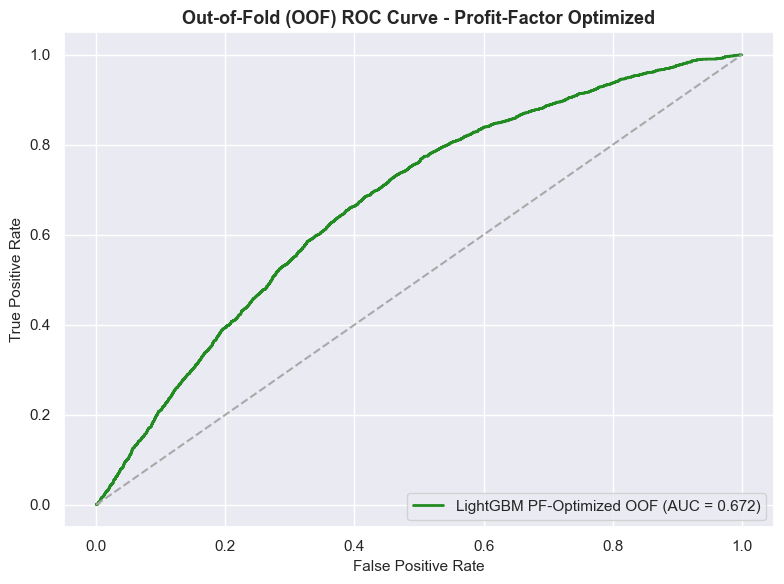

In [103]:
best_params_pf = profit_study.best_params.copy()
best_params_pf['objective'] = 'binary'
best_params_pf['random_state'] = 42
best_params_pf['n_jobs'] = -1
best_params_pf['verbose'] = -1

y_binary = (y_labels == 1).astype(int)
oof_probs_pf = np.zeros(len(X_features))

for train_idx, test_idx in cv.split(X_features):
    X_train, X_test = X_features.iloc[train_idx], X_features.iloc[test_idx]
    y_train = y_binary.iloc[train_idx]
    w_train = sample_weights[train_idx]
    
    model_pf = LGBMClassifier(**best_params_pf)
    model_pf.fit(X_train, y_train, sample_weight=w_train)
    oof_probs_pf[test_idx] = model_pf.predict_proba(X_test)[:, 1]

oof_auc_pf = roc_auc_score(y_binary, oof_probs_pf)
threshold_pf = pd.Series(oof_probs_pf).quantile(0.80)
y_pred_binary_pf = (oof_probs_pf >= threshold_pf).astype(int)

print("=== Out-of-Fold (OOF) Evaluation Report (Profit-Factor Optimized Model) ===")
print(classification_report(y_binary, y_pred_binary_pf))
print(f"Out-of-Fold ROC-AUC: {oof_auc_pf:.4f}")

fpr, tpr, _ = roc_curve(y_binary, oof_probs_pf)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='forestgreen', label=f'LightGBM PF-Optimized OOF (AUC = {oof_auc_pf:.3f})', linewidth=2)
plt.plot([0, 1], [0, 1], color='darkgray', linestyle='--')
plt.title('Out-of-Fold (OOF) ROC Curve - Profit-Factor Optimized', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [77]:
import backtrader as bt
import pandas as pd
import numpy as np

df_bt_pf = df_processed.copy()
df_bt_pf['prob_success'] = oof_probs_pf

primary_longs = (
    (df_bt_pf['Close'] > df_bt_pf['Close'].ewm(span=50).mean()) & 
    (df_bt_pf['ATR'] > df_bt_pf['ATR'].rolling(20).mean())
)
threshold_pf = pd.Series(oof_probs_pf).quantile(0.80)
df_bt_pf['signal'] = (primary_longs & (df_bt_pf['prob_success'] >= threshold_pf)).astype(int)

# 2. Custom Data Feed supporting ATR and signals
class MLATRData(bt.feeds.PandasData):
    lines = ('prob_success', 'signal', 'ATR')
    params = (
        ('prob_success', 'prob_success'),
        ('signal', 'signal'),
        ('ATR', 'ATR'),
    )

class DynamicATRBarrierStrategy(bt.Strategy):
    params = (
        ('tp_mult', 2.5),  # 2.5x ATR Take Profit
        ('sl_mult', 1.0),  # 1.0x ATR Stop Loss
        ('printlog', False),
    )

    def __init__(self):
        self.dataclose = self.datas[0].close
        self.prob_success = self.datas[0].prob_success
        self.signal = self.datas[0].signal
        self.atr = self.datas[0].ATR
        self.orefs = []

    def notify_order(self, order):
        if order.status in [order.Completed, order.Canceled, order.Margin, order.Rejected]:
            self.orefs = [ref for ref in self.orefs if ref != order.ref]

    def next(self):
        if self.orefs:
            return

        if not self.position:
            if self.signal[0] == 1:
                entry_price = self.dataclose[0]
                current_atr = self.atr[0]
                
                tp_price = entry_price + (current_atr * self.params.tp_mult)
                sl_price = entry_price - (current_atr * self.params.sl_mult)

                bracket = self.buy_bracket(
                    size=1,
                    price=entry_price,
                    exectype=bt.Order.Market,
                    stopprice=sl_price,
                    limitprice=tp_price
                )
                self.orefs = [o.ref for o in bracket]

cerebro = bt.Cerebro()
cerebro.addstrategy(DynamicATRBarrierStrategy)

data = MLATRData(
    dataname=df_bt_pf,
    datetime=None,
    open='Open', high='High', low='Low', close='Close', volume='Volume'
)
cerebro.adddata(data)

cerebro.broker.setcash(10000.0)
cerebro.broker.setcommission(commission=0.62, margin=500.0, mult=2.0)

print(f'Starting Portfolio Value: ${cerebro.broker.getvalue():,.2f}')
cerebro.run()
final_val_pf = cerebro.broker.getvalue()
print(f'Final Portfolio Value (PF-Optimized No-Hour): ${final_val_pf:,.2f}')
print(f'Net Strategy Return:                         ${final_val_pf - 10000.0:,.2f}')

Starting Portfolio Value: $10,000.00
Final Portfolio Value (PF-Optimized No-Hour): $9,964.04
Net Strategy Return:                         $-35.96


In [78]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective_profit_factor_no_hour(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 2, 6),
        'num_leaves': trial.suggest_int('num_leaves', 4, 32),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'random_state': 42,
        'n_jobs': -1,
        'verbose': -1
    }
    
    y_binary = (y_labels == 1).astype(int)
    oof_probs_no_hr = np.zeros(len(X_features_no_hr))
    
    for train_idx, test_idx in cv.split(X_features_no_hr):
        X_train, X_test = X_features_no_hr.iloc[train_idx], X_features_no_hr.iloc[test_idx]
        y_train = y_binary.iloc[train_idx]
        w_train = sample_weights[train_idx]
        
        model_no_hr = LGBMClassifier(**params, objective='binary')
        model_no_hr.fit(X_train, y_train, sample_weight=w_train)
        
        oof_probs_no_hr[test_idx] = model_no_hr.predict_proba(X_test)[:, 1]
        
    temp_df = df_processed.copy()
    temp_df['prob_success'] = oof_probs
    
    primary_longs = (
        (temp_df['Close'] > temp_df['Close'].ewm(span=50).mean()) & 
        (temp_df['ATR'] > temp_df['ATR'].rolling(20).mean())
    )
    
    threshold = pd.Series(oof_probs).quantile(0.80)
    selected_signals = primary_longs & (temp_df['prob_success'] >= threshold)
    
    if selected_signals.sum() < 20:
        return 0.0
        
    trade_outcomes = np.zeros(len(temp_df))
    trade_outcomes[y_labels == 1] = 2.5
    trade_outcomes[y_labels == -1] = -1.0
    
    filtered_pnl = trade_outcomes[selected_signals]
    gross_profits = filtered_pnl[filtered_pnl > 0].sum()
    gross_losses = abs(filtered_pnl[filtered_pnl < 0].sum())
    
    if gross_losses == 0:
        return float(len(filtered_pnl))
        
    return gross_profits / gross_losses

print("Running Optuna Profit Factor Optimization (Excluding 'Hour')...")
profit_study_no_hour = optuna.create_study(direction='maximize')
profit_study_no_hour.optimize(objective_profit_factor_no_hour, n_trials=30, show_progress_bar=True)

print(f"Best OOF Profit Factor (No Hour): {profit_study_no_hour.best_value:.4f}")

Running Optuna Profit Factor Optimization (Excluding 'Hour')...


  0%|          | 0/30 [00:00<?, ?it/s]

Best OOF Profit Factor (No Hour): 1.8919


=== Out-of-Fold (OOF) Evaluation Report (Profit-Factor Optimized Model) ===
              precision    recall  f1-score   support

           0       0.76      0.84      0.80      8295
           1       0.42      0.31      0.36      3170

    accuracy                           0.69     11465
   macro avg       0.59      0.57      0.58     11465
weighted avg       0.67      0.69      0.68     11465

Out-of-Fold ROC-AUC: 0.6708


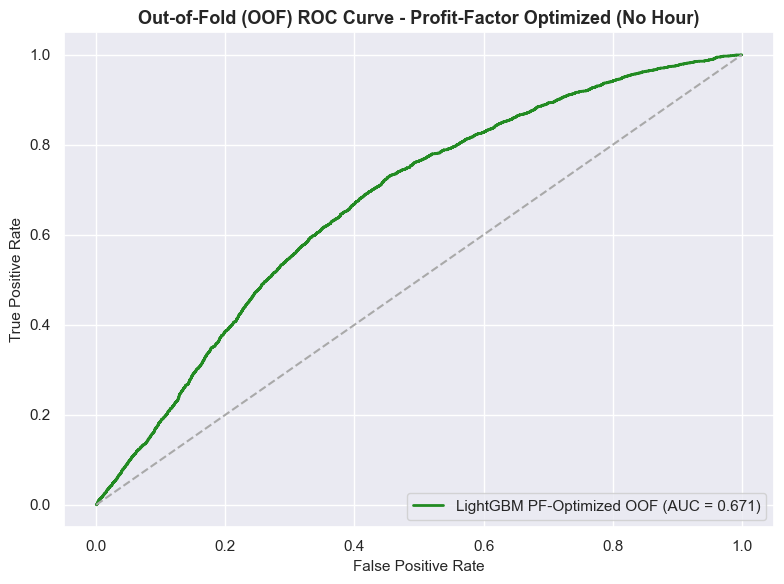

In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, roc_auc_score, roc_curve
from lightgbm import LGBMClassifier

best_params_pf_no_hr = profit_study_no_hour.best_params.copy()
best_params_pf_no_hr['objective'] = 'binary'
best_params_pf_no_hr['random_state'] = 42
best_params_pf_no_hr['n_jobs'] = -1
best_params_pf_no_hr['verbose'] = -1

y_binary = (y_labels == 1).astype(int)
oof_probs_pf_no_hr = np.zeros(len(X_features_no_hr))

for train_idx, test_idx in cv.split(X_features_no_hr):
    X_train, X_test = X_features_no_hr.iloc[train_idx], X_features_no_hr.iloc[test_idx]
    y_train = y_binary.iloc[train_idx]
    w_train = sample_weights[train_idx]
    
    model_pf_no_hr = LGBMClassifier(**best_params_pf_no_hr)
    model_pf_no_hr.fit(X_train, y_train, sample_weight=w_train)
    oof_probs_pf_no_hr[test_idx] = model_pf_no_hr.predict_proba(X_test)[:, 1]

oof_auc_pf_no_hr = roc_auc_score(y_binary, oof_probs_pf_no_hr)

threshold_pf_no_hr = pd.Series(oof_probs_pf_no_hr).quantile(0.80)
y_pred_pf_no_hr = (oof_probs_pf_no_hr >= threshold_pf_no_hr).astype(int)

print("=== Out-of-Fold (OOF) Evaluation Report (Profit-Factor Optimized Model) ===")
print(classification_report(y_binary, y_pred_pf_no_hr))
print(f"Out-of-Fold ROC-AUC: {oof_auc_pf_no_hr:.4f}")

fpr, tpr, _ = roc_curve(y_binary, oof_probs_pf_no_hr)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='forestgreen', label=f'LightGBM PF-Optimized OOF (AUC = {oof_auc_pf_no_hr:.3f})', linewidth=2)
plt.plot([0, 1], [0, 1], color='darkgray', linestyle='--')
plt.title('Out-of-Fold (OOF) ROC Curve - Profit-Factor Optimized (No Hour)', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [81]:
import backtrader as bt
import pandas as pd
import numpy as np

df_bt_pf_no_hr = df_processed.copy()
df_bt_pf_no_hr['prob_success'] = oof_probs_pf_no_hr

primary_longs = (
    (df_bt_pf_no_hr['Close'] > df_bt_pf_no_hr['Close'].ewm(span=50).mean()) & 
    (df_bt_pf_no_hr['ATR'] > df_bt_pf_no_hr['ATR'].rolling(20).mean())
)
threshold_pf_no_hr = pd.Series(oof_probs_pf_no_hr).quantile(0.80)
df_bt_pf_no_hr['signal'] = (primary_longs & (df_bt_pf_no_hr['prob_success'] >= threshold_pf_no_hr)).astype(int)

class MLATRData(bt.feeds.PandasData):
    lines = ('prob_success', 'signal', 'ATR')
    params = (
        ('prob_success', 'prob_success'),
        ('signal', 'signal'),
        ('ATR', 'ATR'),
    )

class DynamicATRBarrierStrategy(bt.Strategy):
    params = (
        ('tp_mult', 2.5),  # 2.5x ATR Take Profit
        ('sl_mult', 1.0),  # 1.0x ATR Stop Loss
        ('printlog', False),
    )

    def __init__(self):
        self.dataclose = self.datas[0].close
        self.prob_success = self.datas[0].prob_success
        self.signal = self.datas[0].signal
        self.atr = self.datas[0].ATR
        self.orefs = []

    def notify_order(self, order):
        if order.status in [order.Completed, order.Canceled, order.Margin, order.Rejected]:
            self.orefs = [ref for ref in self.orefs if ref != order.ref]

    def next(self):
        if self.orefs:
            return

        if not self.position:
            if self.signal[0] == 1:
                entry_price = self.dataclose[0]
                current_atr = self.atr[0]
                
                tp_price = entry_price + (current_atr * self.params.tp_mult)
                sl_price = entry_price - (current_atr * self.params.sl_mult)

                bracket = self.buy_bracket(
                    size=1,
                    price=entry_price,
                    exectype=bt.Order.Market,
                    stopprice=sl_price,
                    limitprice=tp_price
                )
                self.orefs = [o.ref for o in bracket]

cerebro = bt.Cerebro()
cerebro.addstrategy(DynamicATRBarrierStrategy)

data = MLATRData(
    dataname=df_bt_pf_no_hr,
    datetime=None,
    open='Open', high='High', low='Low', close='Close', volume='Volume'
)
cerebro.adddata(data)

cerebro.broker.setcash(10000.0)
cerebro.broker.setcommission(commission=0.62, margin=500.0, mult=2.0)

print(f'Starting Portfolio Value: ${cerebro.broker.getvalue():,.2f}')
cerebro.run()
final_val_pf_no_hr = cerebro.broker.getvalue()
print(f'Final Portfolio Value (PF-Optimized No-Hour): ${final_val_pf_no_hr:,.2f}')
print(f'Net Strategy Return:                         ${final_val_pf_no_hr - 10000.0:,.2f}')


Starting Portfolio Value: $10,000.00
Final Portfolio Value (PF-Optimized No-Hour): $12,400.18
Net Strategy Return:                         $2,400.18


In [83]:
def run_walk_forward_pipeline(X_data, best_params, feature_name="Model"):
    print(f"\n--- Running Walk-Forward Validation: {feature_name} ---")
    
    y_binary = (y_labels == 1).astype(int)
    wfo_probs = np.full(len(X_data), np.nan)  
    tscv = TimeSeriesSplit(n_splits=5)
    
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X_data)):
        X_train, X_test = X_data.iloc[train_idx], X_data.iloc[test_idx]
        y_train = y_binary.iloc[train_idx]
        w_train = sample_weights[train_idx]
        
        model = LGBMClassifier(**best_params)
        model.fit(X_train, y_train, sample_weight=w_train)
        
        
        wfo_probs[test_idx] = model.predict_proba(X_test)[:, 1]
        print(f"Fold {fold+1} completed: Train size = {len(train_idx)}, Test size = {len(test_idx)}")
        
    return wfo_probs
best_params_no_hr = profit_study_no_hour.best_params.copy()
best_params_no_hr.update({'objective': 'binary', 'random_state': 42, 'n_jobs': -1, 'verbose': -1})
wfo_probs_no_hr = run_walk_forward_pipeline(X_features_no_hr, best_params_no_hr, "No-Hour Model")
best_params_hr = profit_study.best_params.copy()
best_params_hr.update({'objective': 'binary', 'random_state': 42, 'n_jobs': -1, 'verbose': -1})
wfo_probs_hr = run_walk_forward_pipeline(X_features, best_params_hr, "Hour-Inclusive Model")

class MLATRData(bt.feeds.PandasData):
    lines = ('prob_success', 'signal', 'ATR')
    params = (('prob_success', 'prob_success'), ('signal', 'signal'), ('ATR', 'ATR'))

class DynamicATRBarrierStrategy(bt.Strategy):
    params = (('tp_mult', 2.5), ('sl_mult', 1.0))

    def __init__(self):
        self.dataclose = self.datas[0].close
        self.signal = self.datas[0].signal
        self.atr = self.datas[0].ATR
        self.orefs = []

    def notify_order(self, order):
        if order.status in [order.Completed, order.Canceled, order.Margin, order.Rejected]:
            self.orefs = [ref for ref in self.orefs if ref != order.ref]

    def next(self):
        if self.orefs:
            return
        if not self.position:
            if self.signal[0] == 1:
                entry_price = self.dataclose[0]
                current_atr = self.atr[0]
                tp_price = entry_price + (current_atr * self.params.tp_mult)
                sl_price = entry_price - (current_atr * self.params.sl_mult)

                bracket = self.buy_bracket(size=1, price=entry_price, exectype=bt.Order.Market, stopprice=sl_price, limitprice=tp_price)
                self.orefs = [o.ref for o in bracket]

def evaluate_in_backtrader(wfo_probs_array, label_str):
    df_wfo = df_processed.copy()
    df_wfo['prob_success'] = wfo_probs_array
    
    df_wfo = df_wfo.dropna(subset=['prob_success'])
    
    primary_longs = (
        (df_wfo['Close'] > df_wfo['Close'].ewm(span=50).mean()) & 
        (df_wfo['ATR'] > df_wfo['ATR'].rolling(20).mean())
    )
    threshold = pd.Series(df_wfo['prob_success']).quantile(0.80)
    df_wfo['signal'] = (primary_longs & (df_wfo['prob_success'] >= threshold)).astype(int)

    cerebro = bt.Cerebro()
    cerebro.addstrategy(DynamicATRBarrierStrategy)

    data = MLATRData(dataname=df_wfo, datetime=None, open='Open', high='High', low='Low', close='Close', volume='Volume')
    cerebro.adddata(data)
    cerebro.broker.setcash(10000.0)
    cerebro.broker.setcommission(commission=0.62, margin=500.0, mult=2.0)

    print(f"\n--- Backtrader WFO Result: {label_str} ---")
    print(f"Starting Portfolio Value: $10,000.00")
    cerebro.run()
    final_val = cerebro.broker.getvalue()
    print(f"Final Portfolio Value:    ${final_val:,.2f}")
    print(f"Net Strategy Return:      ${final_val - 10000.0:,.2f}")
    return final_val

val_no_hr = evaluate_in_backtrader(wfo_probs_no_hr, "No-Hour WFO Model")
val_hr = evaluate_in_backtrader(wfo_probs_hr, "Hour-Inclusive WFO Model")


--- Running Walk-Forward Validation: No-Hour Model ---
Fold 1 completed: Train size = 1915, Test size = 1910
Fold 2 completed: Train size = 3825, Test size = 1910
Fold 3 completed: Train size = 5735, Test size = 1910
Fold 4 completed: Train size = 7645, Test size = 1910
Fold 5 completed: Train size = 9555, Test size = 1910

--- Running Walk-Forward Validation: Hour-Inclusive Model ---
Fold 1 completed: Train size = 1915, Test size = 1910
Fold 2 completed: Train size = 3825, Test size = 1910
Fold 3 completed: Train size = 5735, Test size = 1910
Fold 4 completed: Train size = 7645, Test size = 1910
Fold 5 completed: Train size = 9555, Test size = 1910

--- Backtrader WFO Result: No-Hour WFO Model ---
Starting Portfolio Value: $10,000.00
Final Portfolio Value:    $12,228.48
Net Strategy Return:      $2,228.48

--- Backtrader WFO Result: Hour-Inclusive WFO Model ---
Starting Portfolio Value: $10,000.00
Final Portfolio Value:    $14,789.04
Net Strategy Return:      $4,789.04


In [87]:
class MLATRData(bt.feeds.PandasData):
    lines = ('prob_success', 'signal', 'ATR')
    params = (('prob_success', 'prob_success'), ('signal', 'signal'), ('ATR', 'ATR'))

class DynamicATRBarrierStrategy(bt.Strategy):
    params = (('tp_mult', 2.5), ('sl_mult', 1.0))

    def __init__(self):
        self.dataclose = self.datas[0].close
        self.signal = self.datas[0].signal
        self.atr = self.datas[0].ATR
        self.orefs = []

    def notify_order(self, order):
        if order.status in [order.Completed, order.Canceled, order.Margin, order.Rejected]:
            self.orefs = [ref for ref in self.orefs if ref != order.ref]

    def next(self):
        if self.orefs:
            return
        if not self.position:
            if self.signal[0] == 1:
                entry_price = self.dataclose[0]
                current_atr = self.atr[0]
                tp_price = entry_price + (current_atr * self.params.tp_mult)
                sl_price = entry_price - (current_atr * self.params.sl_mult)

                bracket = self.buy_bracket(size=1, price=entry_price, exectype=bt.Order.Market, stopprice=sl_price, limitprice=tp_price)
                self.orefs = [o.ref for o in bracket]


def run_fold_by_fold_wfo(X_data, best_params, model_label="Model"):
    print(f"\n==============================================")
    print(f"Running Fold-by-Fold WFO Analysis: {model_label}")
    print(f"==============================================")
    
    y_binary = (y_labels == 1).astype(int)
    tscv = TimeSeriesSplit(n_splits=5)
    
    fold_results = []
    
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X_data)):
        X_train, X_test = X_data.iloc[train_idx], X_data.iloc[test_idx]
        y_train = y_binary.iloc[train_idx]
        w_train = sample_weights[train_idx]
        
        model = LGBMClassifier(**best_params)
        model.fit(X_train, y_train, sample_weight=w_train)
        
        test_probs = model.predict_proba(X_test)[:, 1]
        
        df_fold = df_processed.iloc[test_idx].copy()
        df_fold['prob_success'] = test_probs
        
        primary_longs = (
            (df_fold['Close'] > df_fold['Close'].ewm(span=50).mean()) & 
            (df_fold['ATR'] > df_fold['ATR'].rolling(20).mean())
        )
        threshold = pd.Series(test_probs).quantile(0.80)
        df_fold['signal'] = (primary_longs & (df_fold['prob_success'] >= threshold)).astype(int)
        
        cerebro = bt.Cerebro()
        cerebro.addstrategy(DynamicATRBarrierStrategy)
        
        data = MLATRData(dataname=df_fold, datetime=None, open='Open', high='High', low='Low', close='Close', volume='Volume')
        cerebro.adddata(data)
        
        cerebro.broker.setcash(10000.0)
        cerebro.broker.setcommission(commission=0.62, margin=500.0, mult=2.0)
        
        cerebro.addanalyzer(bt.analyzers.TradeAnalyzer, _name='ta')
        
        results = cerebro.run()
        strat = results[0]
        trade_analysis = strat.analyzers.ta.get_analysis()
        
        final_val = cerebro.broker.getvalue()
        net_pnl = final_val - 10000.0
        
        total_trades = trade_analysis.get('total', {}).get('total', 0)
        won_trades = trade_analysis.get('won', {}).get('total', 0)
        lost_trades = trade_analysis.get('lost', {}).get('total', 0)
        win_rate = (won_trades / total_trades * 100) if total_trades > 0 else 0.0
        
        fold_results.append({
            'Fold': fold + 1,
            'Test Size': len(test_idx),
            'Trades': total_trades,
            'Win Rate (%)': round(win_rate, 2),
            'Net PnL ($)': round(net_pnl, 2),
            'Final Value ($)': round(final_val, 2)
        })
        
        print(f"Fold {fold+1} | Trades: {total_trades:3d} | Win Rate: {win_rate:5.1f}% | Net PnL: ${net_pnl:8.2f}")

    summary_df = pd.DataFrame(fold_results)
    print(f"\n--- Summary Table ({model_label}) ---")
    print(summary_df.to_string(index=False))
    return summary_df

best_params_no_hr = profit_study_no_hour.best_params.copy()
best_params_no_hr.update({'objective': 'binary', 'random_state': 42, 'n_jobs': -1, 'verbose': -1})

best_params_hr = profit_study.best_params.copy()
best_params_hr.update({'objective': 'binary', 'random_state': 42, 'n_jobs': -1, 'verbose': -1})

summary_no_hr = run_fold_by_fold_wfo(X_features_no_hr, best_params_no_hr, "No-Hour Model")
summary_hr = run_fold_by_fold_wfo(X_features, best_params_hr, "Hour-Inclusive Model")


Running Fold-by-Fold WFO Analysis: No-Hour Model
Fold 1 | Trades:  17 | Win Rate:  35.3% | Net PnL: $ 1152.15
Fold 2 | Trades:  23 | Win Rate:  34.8% | Net PnL: $ -429.84
Fold 3 | Trades:  28 | Win Rate:  25.0% | Net PnL: $ -897.41
Fold 4 | Trades:  20 | Win Rate:  55.0% | Net PnL: $ 3093.43
Fold 5 | Trades:  13 | Win Rate:  23.1% | Net PnL: $ -617.72

--- Summary Table (No-Hour Model) ---
 Fold  Test Size  Trades  Win Rate (%)  Net PnL ($)  Final Value ($)
    1       1910      17         35.29      1152.15         11152.15
    2       1910      23         34.78      -429.84          9570.16
    3       1910      28         25.00      -897.41          9102.59
    4       1910      20         55.00      3093.43         13093.43
    5       1910      13         23.08      -617.72          9382.28

Running Fold-by-Fold WFO Analysis: Hour-Inclusive Model
Fold 1 | Trades:  15 | Win Rate:  40.0% | Net PnL: $  682.10
Fold 2 | Trades:  18 | Win Rate:  33.3% | Net PnL: $  -81.74
Fold 3 | Trad

In [ ]:
import pandas as pd

def compare_model_features(model_hr, X_hr, model_no_hr, X_no_hr):
    df_hr = pd.DataFrame({
        'Feature': X_hr.columns,
        'Gain_With_Hour': model_hr.booster_.feature_importance(importance_type='gain')
    })
    
    df_no_hr = pd.DataFrame({
        'Feature': X_no_hr.columns,
        'Gain_No_Hour': model_no_hr.booster_.feature_importance(importance_type='gain')
    })
    
    comparison_df = pd.merge(df_hr, df_no_hr, on='Feature', how='outer').fillna(0)
    
    comparison_df['Pct_With_Hour'] = (comparison_df['Gain_With_Hour'] / comparison_df['Gain_With_Hour'].sum()) * 100
    comparison_df['Pct_No_Hour'] = (comparison_df['Gain_No_Hour'] / comparison_df['Gain_No_Hour'].sum()) * 100
    
    comparison_df = comparison_df.sort_values(by='Gain_With_Hour', ascending=False).reset_index(drop=True)
    final_comparison = comparison_df[['Feature', 'Pct_With_Hour', 'Pct_No_Hour']].copy()
    final_comparison['Pct_With_Hour'] = final_comparison['Pct_With_Hour'].round(2)
    final_comparison['Pct_No_Hour'] = final_comparison['Pct_No_Hour'].round(2)
    
    return final_comparison

feature_comparison_table = compare_model_features(model_pf, X_features, model_pf_no_hr, X_features_no_hr)
print(feature_comparison_table.to_string(index=False))

              Feature  Pct_With_Hour  Pct_No_Hour
                 Hour           9.87         0.00
 relative_volume_lag6           3.68        15.14
               SMA_50           2.89         3.41
 relative_volume_lag7           2.58        13.46
            return_24           2.31         2.31
        volatility_24           2.05         2.62
                  ATR           2.05         2.86
               SMA_20           2.01         1.60
               EMA_20           1.79         1.19
      MACD_hist_lag12           1.75         1.22
 relative_volume_lag2           1.65         2.53
  volatility_12_lag12           1.64         1.93
               EMA_50           1.61         2.16
          MACD_signal           1.41         0.70
          close_SMA50           1.37         0.90
 relative_volume_lag4           1.33         1.96
 relative_volume_lag1           1.26         1.83
            MACD_hist           1.26         0.43
         RSI_14_lag11           1.24         0.23


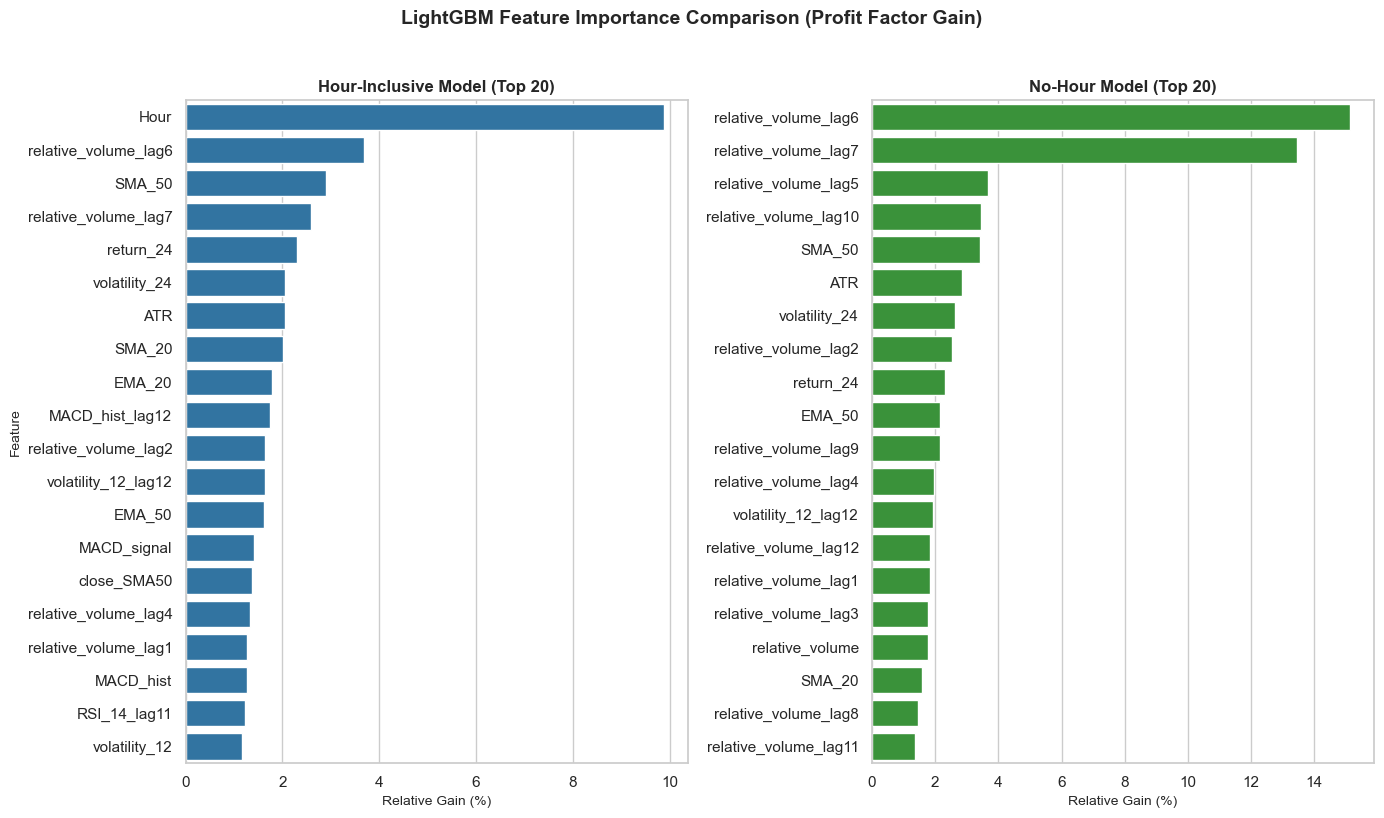

In [113]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_feature_importance_comparison(model_hr, X_hr, model_no_hr, X_no_hr):
    df_hr = pd.DataFrame({
        'Feature': X_hr.columns,
        'Importance': model_hr.booster_.feature_importance(importance_type='gain')
    })
    df_hr['Importance'] = (df_hr['Importance'] / df_hr['Importance'].sum()) * 100
    df_hr = df_hr.sort_values(by='Importance', ascending=False).head(20)
    
    df_no_hr = pd.DataFrame({
        'Feature': X_no_hr.columns,
        'Importance': model_no_hr.booster_.feature_importance(importance_type='gain')
    })
    df_no_hr['Importance'] = (df_no_hr['Importance'] / df_no_hr['Importance'].sum()) * 100
    df_no_hr = df_no_hr.sort_values(by='Importance', ascending=False).head(20)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 8))
    sns.set_theme(style="whitegrid")
    
    sns.barplot(
        x='Importance', 
        y='Feature', 
        data=df_hr, 
        ax=axes[0], 
        color='#1f77b4'
    )
    axes[0].set_title('Hour-Inclusive Model (Top 20)', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Relative Gain (%)', fontsize=10)
    axes[0].set_ylabel('Feature', fontsize=10)
    sns.barplot(
        x='Importance', 
        y='Feature', 
        data=df_no_hr, 
        ax=axes[1], 
        color='#2ca02c'
    )
    axes[1].set_title('No-Hour Model (Top 20)', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Relative Gain (%)', fontsize=10)
    axes[1].set_ylabel('') 
    
    plt.suptitle('LightGBM Feature Importance Comparison (Profit Factor Gain)', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()


plot_feature_importance_comparison(model_pf, X_features, model_pf_no_hr, X_features_no_hr)

In [114]:
import os

os.makedirs('assets', exist_ok=True)

plt.savefig('assets/mnq_feature_importance_comparison.png', dpi=300, bbox_inches='tight')
print("Chart saved successfully to 'assets/mnq_feature_importance_comparison.png'!")
plt.show()

Chart saved successfully to 'assets/mnq_feature_importance_comparison.png'!


<Figure size 640x480 with 0 Axes>

In [115]:
import joblib

joblib.dump(model_pf, 'mnq_lightgbm_model_hour.pkl')
joblib.dump(model_pf_no_hr, 'mnq_lightgbm_model_no_hour.pkl')
joblib.dump(X_features.columns.tolist(), 'mnq_features_cols.pkl')
joblib.dump(X_features_no_hr.columns.tolist(), 'mnq_features_cols_no_hour.pkl')

['mnq_features_cols_no_hour.pkl']

In [123]:
df_no_hour_with_prices = X_features_no_hr.copy()
df_no_hour_with_prices['Close'] = mnq_hr.loc[X_features_no_hr.index,'Close'] # Attach raw close prices
df_no_hour_with_prices.to_parquet("training_features_no_hour.parquet")

df_hour_with_prices = X_features.copy()
df_hour_with_prices['Close'] = mnq_hr.loc[X_features.index, 'Close']
df_hour_with_prices.to_parquet("training_features_hour.parquet")

[NO_HOUR] Successfully loaded model and 99 feature columns.
Loading data from training_features_no_hour.parquet...
Running model inference on dataset...

--- Backtest Results ---
Variant: NO_HOUR
Gross Profits: 0.7728
Gross Losses: 0.2844
Backtest Profit Factor: 2.72


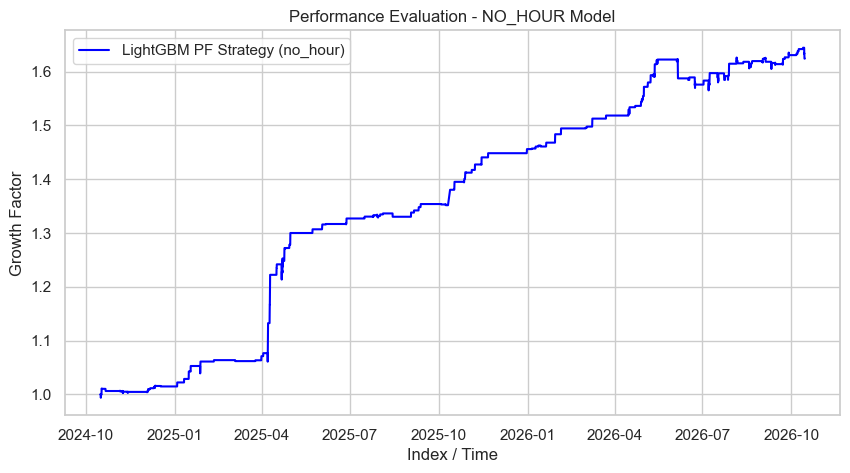

[HOUR] Successfully loaded model and 100 feature columns.
Loading data from training_features_hour.parquet...
Running model inference on dataset...

--- Backtest Results ---
Variant: HOUR
Gross Profits: 3.6196
Gross Losses: 0.8497
Backtest Profit Factor: 4.26


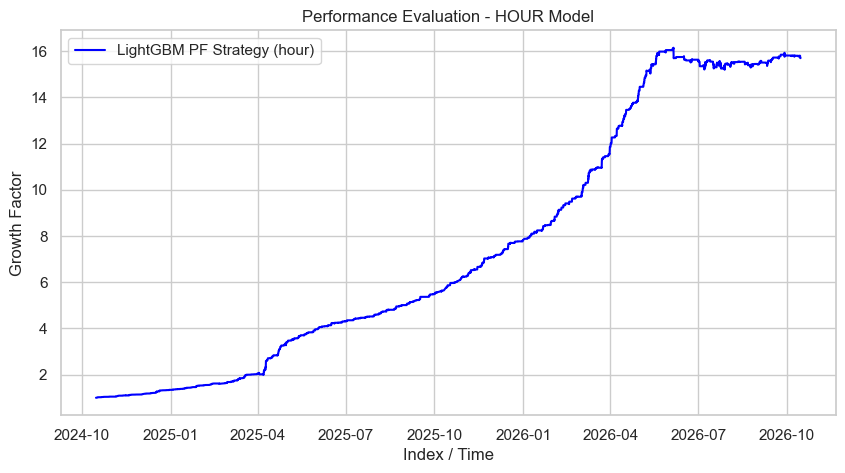

In [ ]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

class MNQBacktestValidator:
    def __init__(self, variant="no_hour", data_path="test_data.parquet"):
        self.variant = variant.lower()
        self.data_path = data_path
        self.model = None
        self.feature_cols = None
        self.load_artifacts()

    def load_artifacts(self):
        """Loads the correct Profit Factor model and its corresponding feature map."""
        if self.variant == "hour":
            model_file = "mnq_lightgbm_model_hour.pkl"
            features_file = "mnq_features_cols.pkl"
        elif self.variant == "no_hour":
            model_file = "mnq_lightgbm_model_no_hour.pkl"
            features_file = "mnq_features_cols_no_hour.pkl"
        else:
            raise ValueError("Invalid variant. Choose 'hour' or 'no_hour'.")

        if not os.path.exists(model_file) or not os.path.exists(features_file):
            raise FileNotFoundError(f"Artifacts for '{self.variant}' not found in root directory.")

        self.model = joblib.load(model_file)
        self.feature_cols = joblib.load(features_file)
        print(f"[{self.variant.upper()}] Successfully loaded model and {len(self.feature_cols)} feature columns.")

    def run_backtest(self):
        """Loads pre-processed feature data, aligns columns, generates signals, and evaluates performance."""
        print(f"Loading data from {self.data_path}...")
        df = pd.read_parquet(self.data_path) if self.data_path.endswith('.parquet') else pd.read_csv(self.data_path)

        X_test = df.reindex(columns=self.feature_cols)
        missing_cols = [col for col in self.feature_cols if col not in df.columns]
        if missing_cols:
            print(f"Warning: The following trained feature columns are missing from the dataset: {missing_cols}")

        print("Running model inference on dataset...")
        df['Signal'] = self.model.predict(X_test, validate_features=True)

      
        if 'Target_Return' in df.columns:
            df['Strategy_Return'] = df['Target_Return'] * df['Signal'].shift(1).fillna(0)
        else:
           
            if 'Close' in df.columns:
                df['Market_Return'] = df['Close'].pct_change()
                df['Strategy_Return'] = df['Market_Return'] * df['Signal'].shift(1).fillna(0)
            else:
                raise KeyError("Could not find 'Close' or 'Target_Return' in the dataframe to calculate returns. Check your parquet contents.")

        gains = df['Strategy_Return'][df['Strategy_Return'] > 0].sum()
        losses = abs(df['Strategy_Return'][df['Strategy_Return'] < 0].sum())
        profit_factor = (gains / losses) if losses != 0 else np.inf

        print("\n--- Backtest Results ---")
        print(f"Variant: {self.variant.upper()}")
        print(f"Gross Profits: {gains:.4f}")
        print(f"Gross Losses: {losses:.4f}")
        print(f"Backtest Profit Factor: {profit_factor:.2f}")

        
        df['Cumulative_Strategy'] = (1 + df['Strategy_Return'].fillna(0)).cumprod()

        plt.figure(figsize=(10, 5))
        plt.plot(df['Cumulative_Strategy'], label=f'LightGBM PF Strategy ({self.variant})', color='blue')
        plt.title(f'Performance Evaluation - {self.variant.upper()} Model')
        plt.xlabel('Index / Time')
        plt.ylabel('Growth Factor')
        plt.legend()
        plt.grid(True)
        plt.show()
if __name__ == "__main__":
    validator_no_hour = MNQBacktestValidator(variant="no_hour", data_path="training_features_no_hour.parquet")
    validator_no_hour.run_backtest()

    validator_hour = MNQBacktestValidator(variant="hour", data_path="training_features_hour.parquet")
    validator_hour.run_backtest()